# Model comparison: sinogram completion (parallel beam)

**Workflow**
1. Train the models with `python -m src.train` (see the README). Every run writes `outputs/2d/checkpoints/<run>/training_stats.json`.
2. Evaluate them on the test split: `python -m src.evaluate --num_samples 200`, which writes
   `model_comparison_metrics.csv` (one row per sample and model), `per_view_mse.csv`, `per_view_var.csv` and
   `ground_truth_metrics.csv` in `results/evaluation/`, versioned with the tables computed from them.
3. Run this notebook (from `results/` or from the project root). Sections 3 and 4 use the variables of sections 1 and 2.

**Section 1**: summary table (test metrics, trainable parameters, training time) and bar charts.
**Section 2**: qualitative comparison on the first test samples, which are also the first samples of the CSV.
**Section 3**: angular reach of the graph models.
**Section 4**: oversmoothing, GCN vs SNN at 12 and 18 layers (4 bis: seeds).
**Section 5**: data regime, U-Net vs U-Net + HLCC loss with 200 and 2000 phantoms, over the seeds.
**Section 6**: moment regression inside the training loop.
**Section 7**: training budget and locality of the graph models (400 epochs, full view graph).

**Statistics.** Every comparison pairs two models on the same test samples: change of the mean with a paired
bootstrap 95 % interval and a paired Wilcoxon signed-rank test (`src/statistics.py`).
- *Confirmatory*: only the criterion of section 4 (SNN vs GCN at 12 and 18 layers, seed 0), fixed before the test
  evaluation. It requires all four of its tests at p < 0.05 (intersection-union test), so it needs no correction.
- *Exploratory*: every other p-value. `p (Holm)` is the Holm-adjusted p-value over the rows of its table (one table
  = one question).
- These tests compare two *trained networks*. A claim about an architecture or a loss must also hold over the seed
  replicas (sections 4 bis and 5).

The tables are exported to `results/tables/` (CSV + LaTeX) and the figures of sections 3 and 4 to `results/figures/` (PDF).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

# Works from results/ (the VS Code default) as well as from the project root.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError(f"Run this notebook from inside the repository (results/ or the project root), not from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import GeometryConfig
from src.dataset import SinogramCompletionDataset
from src.geometry import ParallelGeometry, fbp_reconstruction
from src.metrics import sinogram_metrics
from src.models.factory import BASELINES, get_model, parse_full_model_name, parse_model_name, run_name_of
from src.paths import CHECKPOINT_DIR, EVALUATION_DIR, RESULTS_DIR

EVAL_DIR = EVALUATION_DIR
# Versioned: the figures (PDF) and tables (CSV + LaTeX) of the thesis.
FIG_DIR, TABLE_DIR = RESULTS_DIR / "figures", RESULTS_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
LATEX_SYMBOLS = {"±": r"$\pm$", "→": r"$\rightarrow$", "ρ": r"$\rho$", "≥": r"$\geq$", "°": r"$^\circ$", "×": r"$\times$"}


def export_table(table: pd.DataFrame, name: str) -> None:
    """Write a displayed table to results/tables/<name>.csv and <name>.tex (escaped, ready for \\input)."""
    table.to_csv(TABLE_DIR / f"{name}.csv")
    latex = table.to_latex(escape=True, float_format="{:.3g}".format)
    for symbol, command in LATEX_SYMBOLS.items():
        latex = latex.replace(symbol, command)
    (TABLE_DIR / f"{name}.tex").write_text(latex)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
# Thesis figures are drawn at the text width of the report, so that their text prints at 7-8 pt.
THESIS_W = 6.06  # in
plt.rcParams.update({"font.family": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 8,
                     "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "legend.fontsize": 7, "pdf.fonttype": 42})

## 1. Quantitative summary

Test metrics from `model_comparison_metrics.csv`, reported as **mean ± std over the test samples**:
- `*_wedge`: sinogram metrics restricted to the missing views, the only views a model actually predicts; `ssim`: whole sinogram.
- `img_*`: image metrics after FBP of the completed sinogram, against the phantom.

Every model here is trained on the 2000 phantoms of the protocol, with the seed 0. The seed replicas (`_S1`) are
compared in section 4 bis, the runs of the data-regime study (`_N200`: 200 phantoms) in section 5, the U-Net trained
through the moment regression (`_PL4`) in section 6; the training cost of every network is in the table below the chart.

In [2]:
import re

from src.statistics import holm, paired_bootstrap

METRIC_COLS = ["mse_wedge", "psnr_wedge", "ssim_wedge", "ssim", "img_psnr", "img_ssim"]
FORMATS = {"mse_wedge": "{:.2e}", "psnr_wedge": "{:.2f}", "ssim_wedge": "{:.4f}",
           "ssim": "{:.4f}", "img_psnr": "{:.2f}", "img_ssim": "{:.4f}"}


def is_projected(model_name: str) -> bool:
    """True for "<model>_P<k>": the model followed by the HLCC moment regression (no training)."""
    return parse_full_model_name(model_name).projection_order is not None


def is_data_study(model_name: str) -> bool:
    """True for the runs of the data-regime study ("_N200": another training set), compared in section 5."""
    return any(re.fullmatch(r"N\d+", tag) for tag in parse_full_model_name(model_name).tags)


def is_replica(model_name: str) -> bool:
    """True for "<run>_S<k>": the same configuration trained with another seed, compared in section 4 bis."""
    return any(re.fullmatch(r"S\d+", tag) for tag in parse_full_model_name(model_name).tags)


def is_loop_trained(model_name: str) -> bool:
    """True for "<run>_PL<K>": trained THROUGH the moment regression (train.py --projection_order K), section 6."""
    return any(re.fullmatch(r"PL\d+", tag) for tag in parse_full_model_name(model_name).tags)


def format_change(change: dict) -> str:
    """"+1.2 % [-0.5, +3.0]": relative change of the mean and its paired bootstrap 95 % interval."""
    return f"{100 * change['effect']:+.1f} % [{100 * change['ci_low']:+.1f}, {100 * change['ci_high']:+.1f}]"


def paired_change(reference: pd.Series, candidate: pd.Series) -> dict:
    """Change of the mean mse_wedge from reference to candidate on the same test samples.

    Paired bootstrap 95 % interval and paired Wilcoxon p-value (src/statistics.py). "_p" keeps the raw p-value for
    with_holm, which adds the Holm-adjusted p-value over the rows of the table.
    """
    a, b = reference.align(candidate, join="inner")
    change = paired_bootstrap(b.to_numpy(), a.to_numpy())
    return {"mse_wedge": f"{a.mean():.2e} → {b.mean():.2e}", "Change [95 % CI]": format_change(change),
            "Better on": f"{(b < a).sum()} / {len(a)}", "Wilcoxon p": f"{change['p_value']:.2g}",
            "_p": change["p_value"]}


def with_holm(table: pd.DataFrame) -> pd.DataFrame:
    """Exploratory tests: Holm correction over the rows of the table (the family is the table)."""
    table = table.copy()
    table["p (Holm)"] = [f"{p:.2g}" for p in holm(table.pop("_p").to_numpy())]
    return table


def unprojected(model_name: str) -> str:
    return model_name[: model_name.rfind("_P")] if is_projected(model_name) else model_name

csv_path = EVAL_DIR / "model_comparison_metrics.csv"
metrics = pd.read_csv(csv_path)
outdated = sorted(set(METRIC_COLS) - set(metrics.columns))
if outdated:
    raise ValueError(f"{csv_path} has an outdated format (no {outdated}): re-run python -m src.evaluate")

# Sample == -1 is the FBP of the ground-truth sinogram: the ceiling of the image metrics.
fbp_reference = metrics[metrics["Sample"] < 0]
results = metrics[metrics["Sample"] >= 0]
n_samples = results["Sample"].nunique()


grouped = results.groupby("Model", sort=False)[METRIC_COLS]
mean, std = grouped.mean(), grouped.std()
order = list(mean["mse_wedge"].sort_values().index)  # the checkpoint-selection metric of train.py, best first
trained_order = [m for m in order if not is_projected(m)]                       # every network (training cost table)
def is_budget_or_graph_variant(model_name: str) -> bool:
    """True for "<run>_E<epochs>" (another training budget) and "<run>_Full" (full view graph), section 7."""
    return any(re.fullmatch(r"E\d+|Full", tag) for tag in parse_full_model_name(model_name).tags)


def is_side_run(model_name: str) -> bool:
    return (is_data_study(model_name) or is_replica(model_name) or is_loop_trained(model_name)
            or is_budget_or_graph_variant(model_name))


raw_order = [m for m in trained_order if not is_side_run(m)]  # the protocol: 2000 phantoms, seed 0, plain training
projected_order = [m for m in order if is_projected(m) and not is_side_run(m)]

summary = pd.DataFrame(index=pd.Index(order, name="Model"))
for col in METRIC_COLS:
    fmt = FORMATS[col]
    summary[col] = [f"{fmt.format(mean.loc[m, col])} ± {fmt.format(std.loc[m, col])}" for m in order]

# Ceilings of the image metrics, for every test sample (src/evaluate.py): FBP of the ground-truth sinogram, and FBP of
# a perfect completion (the noisy measured views and the true missing views), the ceiling of a completion under hard
# data consistency.
raw_table = summary.loc[raw_order]
ground_truth_path = EVAL_DIR / "ground_truth_metrics.csv"
if ground_truth_path.exists():
    ground_truth_metrics = pd.read_csv(ground_truth_path).set_index("Sample").sort_index()
    ceilings = {"Ground-truth sinogram (FBP)": ""}
    if "oracle_img_psnr" in ground_truth_metrics:
        ceilings["Perfect completion (FBP)"] = "oracle_"
    for label, prefix in ceilings.items():
        ceiling_row = {col: "—" for col in METRIC_COLS}
        for col in ("img_psnr", "img_ssim"):
            values = ground_truth_metrics[prefix + col]
            ceiling_row[col] = f"{FORMATS[col].format(values.mean())} ± {FORMATS[col].format(values.std())}"
        raw_table = pd.concat([raw_table, pd.DataFrame([ceiling_row], index=pd.Index([label], name="Model"))])
        print(f"Ceiling of the image metrics, {label}, mean over {len(ground_truth_metrics)} samples: "
              f"img_psnr = {ceiling_row['img_psnr']} dB, img_ssim = {ceiling_row['img_ssim']}")
    if "oracle_img_psnr" in ground_truth_metrics:
        # The PSNR of the ceiling spans tens of dB between phantoms, so a mean PSNR is pulled by the easy phantoms:
        # the gap of every model to the perfect completion is taken per sample, and summarised by its median.
        oracle_psnr, oracle_ssim = ground_truth_metrics["oracle_img_psnr"], ground_truth_metrics["oracle_img_ssim"]
        gap_rows = {}
        for m in raw_order:
            model_metrics = results[results["Model"] == m].set_index("Sample").sort_index()
            gap_psnr, gap_ssim = oracle_psnr - model_metrics["img_psnr"], oracle_ssim - model_metrics["img_ssim"]
            gap_rows[m] = {
                "img_psnr (median)": f"{model_metrics['img_psnr'].median():.2f}",
                "PSNR gap, median [IQR] (dB)":
                    f"{gap_psnr.median():.1f} [{gap_psnr.quantile(0.25):.1f}, {gap_psnr.quantile(0.75):.1f}]",
                "img_ssim (median)": f"{model_metrics['img_ssim'].median():.4f}",
                "SSIM gap, median [IQR]":
                    f"{gap_ssim.median():.3f} [{gap_ssim.quantile(0.25):.3f}, {gap_ssim.quantile(0.75):.3f}]",
            }
        gap_rows["Perfect completion (FBP)"] = {"img_psnr (median)": f"{oracle_psnr.median():.2f}",
                                                "PSNR gap, median [IQR] (dB)": "—",
                                                "img_ssim (median)": f"{oracle_ssim.median():.4f}",
                                                "SSIM gap, median [IQR]": "—"}
        ceiling_gap = pd.DataFrame.from_dict(gap_rows, orient="index").rename_axis("Model")
        print("Gap of the FBP image to the perfect completion, per test sample (median and interquartile range):")
        display(ceiling_gap)
        export_table(ceiling_gap, "image_ceiling_gap")
elif not fbp_reference.empty:
    ceiling = fbp_reference.iloc[0]
    print(f"Ceiling of the image metrics (FBP of the ground-truth sinogram, SAMPLE 0 ONLY: re-run src.evaluate for "
          f"the mean): img_psnr = {ceiling['img_psnr']:.2f} dB, img_ssim = {ceiling['img_ssim']:.4f}")
print(f"Test split: {n_samples} samples. Raw models, sorted by mse_wedge:")
display(raw_table)
export_table(raw_table, "test_metrics_raw")

# The same models followed by the HLCC moment regression, paired with their raw version on the same test samples.
per_sample = {m: results[results["Model"] == m].set_index("Sample").sort_index() for m in order}
projection_rows = []
for name in sorted(projected_order, key=lambda m: raw_order.index(unprojected(m)) if unprojected(m) in raw_order else len(order)):
    base = unprojected(name)
    if base not in per_sample:
        continue
    raw, projected = per_sample[base]["mse_wedge"].align(per_sample[name]["mse_wedge"], join="inner")
    change = paired_change(raw, projected)
    projection_rows.append({
        "Model": base, "Projection": name[len(base) + 1:],
        "mse_wedge": f"{raw.mean():.2e}", "mse_wedge + projection": f"{projected.mean():.2e}",
        **{key: value for key, value in change.items() if key != "mse_wedge"},
        "img_psnr": f"{mean.loc[base, 'img_psnr']:.2f} → {mean.loc[name, 'img_psnr']:.2f}",
        "img_ssim": f"{mean.loc[base, 'img_ssim']:.4f} → {mean.loc[name, 'img_ssim']:.4f}",
    })
if projection_rows:
    print("\nThe same models followed by the HLCC moment regression of orders 0..k on the missing views "
          "(_P<k>, no training), paired comparison on mse_wedge (exploratory, Holm over the table):")
    projection_table = with_holm(pd.DataFrame(projection_rows).set_index("Model"))
    display(projection_table)
    export_table(projection_table, "test_metrics_p4")


Ceiling of the image metrics, Ground-truth sinogram (FBP), mean over 200 samples: img_psnr = 38.24 ± 10.66 dB, img_ssim = 0.9614 ± 0.0325
Ceiling of the image metrics, Perfect completion (FBP), mean over 200 samples: img_psnr = 37.69 ± 9.87 dB, img_ssim = 0.9564 ± 0.0405
Gap of the FBP image to the perfect completion, per test sample (median and interquartile range):


,img_psnr (median),"PSNR gap, median [IQR] (dB)",img_ssim (median),"SSIM gap, median [IQR]"
Model,,,,
UNet2D,23.26,"13.3 [10.0, 19.6]",0.5397,"0.455 [0.256, 0.557]"
UNet2dHLCC,23.62,"13.4 [10.2, 19.9]",0.5257,"0.473 [0.277, 0.580]"
SNN_L18,20.07,"15.1 [11.8, 23.2]",0.4517,"0.535 [0.403, 0.628]"
GCN_L18,19.48,"15.6 [12.7, 23.4]",0.4066,"0.588 [0.416, 0.659]"
SNN_L12,19.20,"15.6 [12.5, 24.4]",0.3913,"0.594 [0.439, 0.668]"
GCN_L12,19.28,"15.6 [12.8, 23.9]",0.3771,"0.613 [0.465, 0.704]"
PeriodicInterp,16.15,"19.0 [15.3, 28.1]",0.3483,"0.637 [0.520, 0.728]"
LinearInterp,15.39,"19.9 [15.8, 28.2]",0.2387,"0.741 [0.576, 0.801]"
GCN_L6,17.55,"17.0 [13.6, 25.9]",0.3014,"0.679 [0.556, 0.736]"


Test split: 200 samples. Raw models, sorted by mse_wedge:


,mse_wedge,psnr_wedge,ssim_wedge,ssim,img_psnr,img_ssim
Model,,,,,,
UNet2D,8.15e-04 ± 1.10e-03,33.43 ± 4.67,0.8865 ± 0.0629,0.9178 ± 0.0458,23.35 ± 3.45,0.5337 ± 0.1580
UNet2dHLCC,8.17e-04 ± 1.16e-03,33.73 ± 5.09,0.8913 ± 0.0637,0.9214 ± 0.0463,23.43 ± 3.45,0.5282 ± 0.1723
SNN_L18,1.93e-03 ± 2.60e-03,29.13 ± 3.91,0.7994 ± 0.0803,0.8557 ± 0.0581,20.96 ± 3.34,0.4367 ± 0.1235
GCN_L18,2.40e-03 ± 3.07e-03,28.20 ± 4.01,0.7650 ± 0.0885,0.8310 ± 0.0640,20.25 ± 3.35,0.4046 ± 0.1282
SNN_L12,2.61e-03 ± 2.88e-03,27.49 ± 3.65,0.7463 ± 0.0793,0.8175 ± 0.0573,20.11 ± 3.44,0.3931 ± 0.1228
GCN_L12,2.70e-03 ± 3.26e-03,27.42 ± 3.64,0.7400 ± 0.0807,0.8131 ± 0.0583,20.13 ± 3.41,0.3651 ± 0.1235
PeriodicInterp,6.56e-03 ± 7.07e-03,23.62 ± 4.00,0.6633 ± 0.0976,0.7582 ± 0.0702,16.65 ± 3.52,0.3270 ± 0.1125
LinearInterp,8.24e-03 ± 8.91e-03,22.66 ± 4.03,0.6874 ± 0.0937,0.7754 ± 0.0676,15.95 ± 3.48,0.2493 ± 0.1113
GCN_L6,9.13e-03 ± 1.02e-02,21.57 ± 2.75,0.5262 ± 0.0634,0.6598 ± 0.0459,18.49 ± 3.48,0.3040 ± 0.1059



The same models followed by the HLCC moment regression of orders 0..k on the missing views (_P<k>, no training), paired comparison on mse_wedge (exploratory, Holm over the table):


,Projection,mse_wedge,mse_wedge + projection,Change [95 % CI],Better on,Wilcoxon p,img_psnr,img_ssim,p (Holm)
Model,,,,,,,,,
UNet2D,P4,8.15e-04,7.26e-04,"-11.0 % [-12.5, -9.4]",189 / 200,1.8e-31,23.35 → 23.41,0.5337 → 0.5369,3.6e-31
UNet2dHLCC,P4,8.17e-04,7.36e-04,"-9.9 % [-11.8, -8.0]",185 / 200,1.7e-29,23.43 → 23.47,0.5282 → 0.5304,1.7e-29
SNN_L18,P4,1.93e-03,1.47e-03,"-23.7 % [-27.7, -19.5]",199 / 200,1.6e-34,20.96 → 21.15,0.4367 → 0.4464,1.3e-33
GCN_L18,P4,2.40e-03,1.84e-03,"-23.4 % [-26.9, -19.7]",198 / 200,1.5e-34,20.25 → 20.47,0.4046 → 0.4170,1.3e-33
SNN_L12,P4,2.61e-03,1.89e-03,"-27.5 % [-30.6, -24.5]",200 / 200,1.4e-34,20.11 → 20.39,0.3931 → 0.4141,1.3e-33
GCN_L12,P4,2.70e-03,1.84e-03,"-31.7 % [-35.2, -28.1]",200 / 200,1.4e-34,20.13 → 20.46,0.3651 → 0.3831,1.3e-33
PeriodicInterp,P4,6.56e-03,4.28e-03,"-34.8 % [-38.3, -30.8]",199 / 200,1.6e-34,16.65 → 17.17,0.3270 → 0.3473,1.3e-33
GCN_L6,P4,9.13e-03,2.64e-03,"-71.0 % [-73.3, -68.5]",200 / 200,1.4e-34,18.49 → 19.52,0.3040 → 0.3722,1.3e-33
SNN_L6,P4,9.27e-03,2.66e-03,"-71.3 % [-73.6, -68.8]",200 / 200,1.4e-34,18.57 → 19.66,0.3099 → 0.3783,1.3e-33


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (125 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


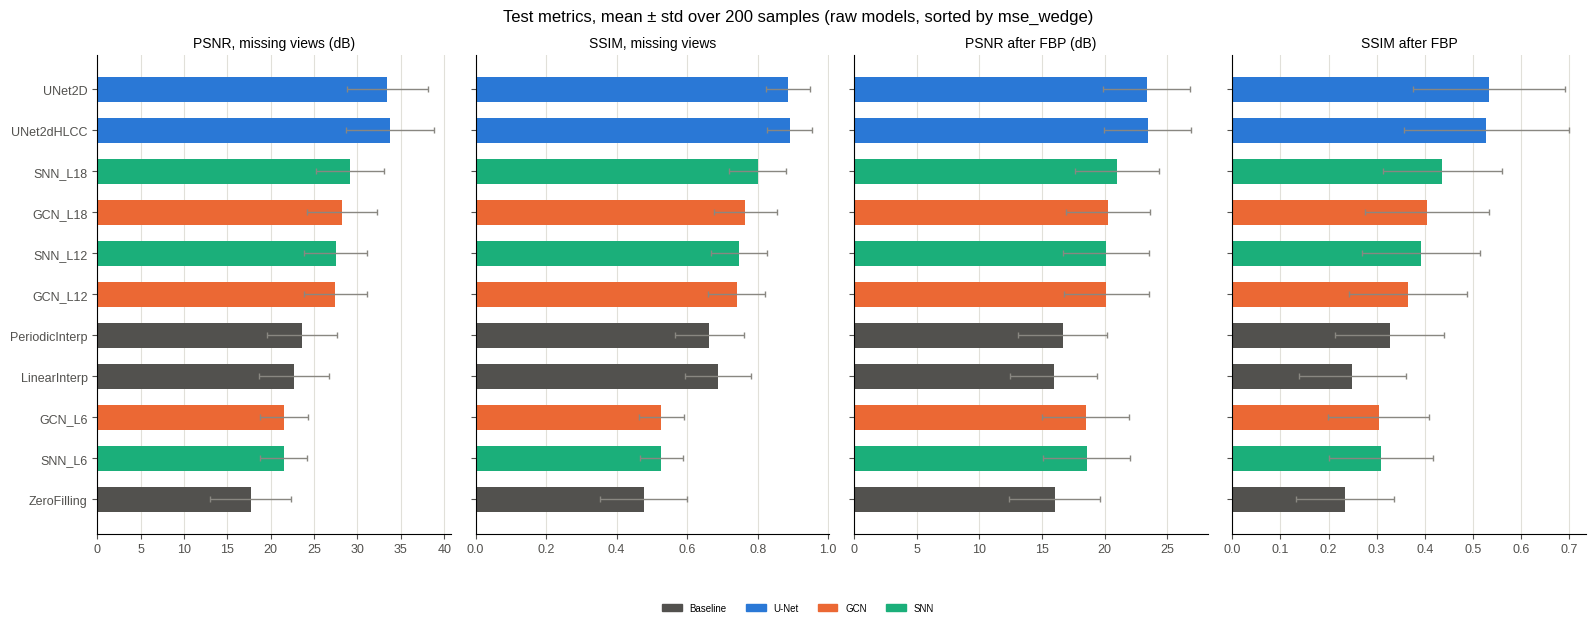

In [3]:
from src.plotting import FAMILY_COLORS
from src.plotting import model_family as family

# Colour = model family, whatever the rank; every bar is also named on the axis.
PLOT_METRICS = [("psnr_wedge", "PSNR, missing views (dB)"), ("ssim_wedge", "SSIM, missing views"),
                ("img_psnr", "PSNR after FBP (dB)"), ("img_ssim", "SSIM after FBP")]


y = np.arange(len(raw_order))
bar_colors = [FAMILY_COLORS.get(family(m), "#898781") for m in raw_order]
fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(4 * len(PLOT_METRICS), 0.4 * len(raw_order) + 1.8), sharey=True)
for ax, (col, title) in zip(axes, PLOT_METRICS):
    ax.barh(y, mean.loc[raw_order, col], xerr=std.loc[raw_order, col], height=0.6, color=bar_colors,
            error_kw={"elinewidth": 1.0, "ecolor": "#898781", "capsize": 2})
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors="#52514e", labelsize=9)
axes[0].set_yticks(y)
axes[0].set_yticklabels(raw_order)
axes[0].invert_yaxis()  # best model (lowest mse_wedge) on top

present = [f for f in FAMILY_COLORS if f in {family(m) for m in raw_order}]
fig.legend([plt.Rectangle((0, 0), 1, 1, color=FAMILY_COLORS[f]) for f in present], present,
           loc="lower center", ncol=len(present), frameon=False)
fig.suptitle(f"Test metrics, mean ± std over {n_samples} samples (raw models, sorted by mse_wedge)", fontsize=12)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

### Training cost and hardware

One row per trained network (a `_P<k>` variant is the same network followed by the HLCC moment regression: no
training, no parameter). Training time includes the validation of every epoch; GPU-hours = training time x GPUs.
Peak VRAM = peak memory allocated by PyTorch on one GPU during a training step, with the per-GPU batch of the run:
recorded by `train.py`, or measured afterwards by `scripts/measure_peak_vram.py` for the older runs.


In [4]:
peak_path = TABLE_DIR / "peak_vram.csv"
measured = pd.read_csv(peak_path).set_index("run") if peak_path.exists() else pd.DataFrame()
FAMILY_RANK = {"Baseline": 0, "U-Net": 1, "GCN": 2, "SNN": 3}
cost_order = sorted(trained_order, key=lambda m: (FAMILY_RANK.get(family(m), 9), parse_model_name(m)[1].get("num_layers", 0), m))


def recorded(stats: dict, run: str, key: str, measured_key: str):
    """A hardware field of training_stats.json, or the later measurement of scripts/measure_peak_vram.py."""
    if key in stats:
        return stats[key]
    return measured.loc[run, measured_key] if run in measured.index else np.nan


cost_rows = []
for name in cost_order:
    if parse_model_name(name)[0] in BASELINES:
        cost_rows.append({"Model": name, "Parameters": "0"})
        continue
    run = run_name_of(name)
    stats_path = CHECKPOINT_DIR / run / "training_stats.json"
    if not stats_path.exists():
        print(f"[skipped] {name}: no {stats_path}")
        continue
    stats = json.loads(stats_path.read_text())
    seconds, epochs, gpus = stats["training_time_seconds"], stats["epochs_run"], stats.get("world_size", 1)
    repeats = stats.get("train_repeats", 1)
    cost_rows.append({
        "Model": name,
        "Parameters": f"{stats['num_params']:,}",
        "Training phantoms": f"{stats['n_samples']}" + (f" × {repeats}" if repeats > 1 else ""),
        "GPU": recorded(stats, run, "device", "gpu"),
        "GPUs": str(gpus),
        "VRAM / GPU (GiB)": f"{recorded(stats, run, 'gpu_memory_gib', 'gpu_memory_gib'):.1f}",
        "Peak VRAM / GPU (GiB)": f"{recorded(stats, run, 'peak_memory_gib', 'peak_memory_gib'):.2f}",
        "Epochs (best)": f"{epochs} ({stats['best']['best_epoch']})",
        "Training time": f"{int(seconds // 3600)} h {int(seconds % 3600 // 60):02d} min",
        "Time / epoch (s)": f"{seconds / epochs:.1f}",
        "GPU-hours": f"{seconds / 3600 * gpus:.1f}",
    })
cost_table = pd.DataFrame(cost_rows).set_index("Model").fillna("—")
display(cost_table)
export_table(cost_table, "training_cost")


,Parameters,Training phantoms,GPU,GPUs,VRAM / GPU (GiB),Peak VRAM / GPU (GiB),Epochs (best),Training time,Time / epoch (s),GPU-hours
Model,,,,,,,,,,
LinearInterp,0,—,—,—,—,—,—,—,—,—
PeriodicInterp,0,—,—,—,—,—,—,—,—,—
ZeroFilling,0,—,—,—,—,—,—,—,—,—
UNet2D,"2,141,249",2000,Tesla K80,8,11.2,0.35,200 (103),0 h 51 min,15.6,6.9
UNet2D_N200,"2,141,249",200 × 10,Tesla K80,8,11.2,0.35,200 (72),0 h 51 min,15.5,6.9
UNet2D_N200_S1,"2,141,249",200 × 10,Tesla K80,8,11.2,0.36,200 (101),0 h 51 min,15.5,6.9
UNet2D_N200_S2,"2,141,249",200 × 10,Tesla K80,8,11.2,0.36,200 (106),0 h 51 min,15.5,6.9
UNet2D_PL4,"2,141,249",2000,Tesla K80,8,11.2,0.36,200 (116),0 h 51 min,15.6,6.9
UNet2D_S1,"2,141,249",2000,Tesla K80,8,11.2,0.36,200 (113),0 h 51 min,15.5,6.9


## 2. Qualitative comparison

The first `NUM_VIZ_SAMPLES` test samples (samples 0, 1, ... of the CSV), for the models of `VIZ_MODELS` (edit the
list to look at another model). `UNet2D_P4` is the same U-Net followed by the HLCC moment regression: compare it
with the `UNet2D` figure on the same samples (the other `_P4` variants are compared in sections 1 and 3 bis).
Columns: incomplete input | completed sinogram | ground truth | FBP of the ground truth | FBP of the completed sinogram.

- The three sinograms of a row share the grey scale of the ground truth, and the FBP images the range [0, 1] of the
  phantom, so that a washed-out prediction looks washed out. Dashed lines: limits of the acquired window.
- The metrics above each prediction are computed exactly as in `src/evaluate.py`; a mismatch with the CSV
  (reported at the end) means that the CSV was produced by other checkpoints.

In [5]:
torch.backends.cudnn.enabled = False  # Tesla K80, as in src/evaluate.py
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

NUM_VIZ_SAMPLES = 3
VIZ_MODELS = ["LinearInterp", "UNet2D", "UNet2D_P4", "GCN_L18", "SNN_L18"]  # every raw model stays loaded (section 4)
NOISE_LEVEL = 1e5  # must match the --noise_level of src.evaluate

geometry_config = GeometryConfig()
geom = ParallelGeometry.from_config(geometry_config)
missing_views = ~geom.acquired_view_mask
# Test samples are drawn from a per-index seed: sample i here is sample i of the CSV.
dataset = SinogramCompletionDataset(NUM_VIZ_SAMPLES, split="test", noise_level=NOISE_LEVEL, geometry_config=geometry_config)

step = geometry_config.angle_step_deg
angles_deg = np.rad2deg(geom.angles)
det_half_mm = geometry_config.det_col_count * geometry_config.det_pixel_size_mm / 2.0
sino_extent = [angles_deg[0] - step / 2, angles_deg[-1] + step / 2, -det_half_mm, det_half_mm]
image_extent = [*geometry_config.image_extent_mm[1], *geometry_config.image_extent_mm[0]]
window_edges = [geometry_config.angle_min_deg - step / 2, geometry_config.angle_max_deg + step / 2]

models = {}
# The raw models, plus the variants of VIZ_MODELS that are not raw (e.g. UNet2D_P4)
for name in [*raw_order, *(m for m in VIZ_MODELS if m not in raw_order)]:
    try:
        models[name], _ = get_model(name, device, geometry_config=geometry_config)
    except (FileNotFoundError, ValueError, RuntimeError) as exc:
        print(f"[skipped] {name}: {str(exc).splitlines()[0]}")
print(f"Loaded {len(models)} models: {list(models)}")

[+] Loaded UNet2D from /home/jdq/Master_Thesis/outputs/2d/checkpoints/UNet2D/best_model.pt (config: {'filters': 32})
[+] Loaded UNet2dHLCC from /home/jdq/Master_Thesis/outputs/2d/checkpoints/UNet2dHLCC/best_model.pt (config: {'filters': 32})


[+] Loaded SNN_L18 from /home/jdq/Master_Thesis/outputs/2d/checkpoints/SNN_L18/best_model.pt (config: {'num_stalks': 32, 'num_layers': 18, 'k': 12, 'sigma_deg': 5.0, 'graph_type': 'knn', 'normalization': 'sym', 'grad_checkpoint': False})
[+] Loaded GCN_L18 from /home/jdq/Master_Thesis/outputs/2d/checkpoints/GCN_L18/best_model.pt (config: {'num_stalks': 32, 'num_layers': 18, 'k': 12, 'sigma_deg': 5.0, 'graph_type': 'knn', 'normalization': 'sym', 'grad_checkpoint': False})
[+] Loaded SNN_L12 from /home/jdq/Master_Thesis/outputs/2d/checkpoints/SNN_L12/best_model.pt (config: {'num_stalks': 32, 'num_layers': 12, 'k': 12, 'sigma_deg': 5.0, 'graph_type': 'knn', 'normalization': 'sym', 'grad_checkpoint': False})
[+] Loaded GCN_L12 from /home/jdq/Master_Thesis/outputs/2d/checkpoints/GCN_L12/best_model.pt (config: {'num_stalks': 32, 'num_layers': 12, 'k': 12, 'sigma_deg': 5.0, 'graph_type': 'knn', 'normalization': 'sym', 'grad_checkpoint': False})


[+] Loaded GCN_L6 from /home/jdq/Master_Thesis/outputs/2d/checkpoints/GCN_L6/best_model.pt (config: {'num_stalks': 32, 'num_layers': 6, 'k': 12, 'sigma_deg': 5.0, 'graph_type': 'knn', 'normalization': 'sym', 'grad_checkpoint': False})
[+] Loaded SNN_L6 from /home/jdq/Master_Thesis/outputs/2d/checkpoints/SNN_L6/best_model.pt (config: {'num_stalks': 32, 'num_layers': 6, 'k': 12, 'sigma_deg': 5.0, 'graph_type': 'knn', 'normalization': 'sym', 'grad_checkpoint': False})
[+] Loaded UNet2D from /home/jdq/Master_Thesis/outputs/2d/checkpoints/UNet2D/best_model.pt (config: {'filters': 32})
Loaded 12 models: ['UNet2D', 'UNet2dHLCC', 'SNN_L18', 'GCN_L18', 'SNN_L12', 'GCN_L12', 'PeriodicInterp', 'LinearInterp', 'GCN_L6', 'SNN_L6', 'ZeroFilling', 'UNet2D_P4']


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (218 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


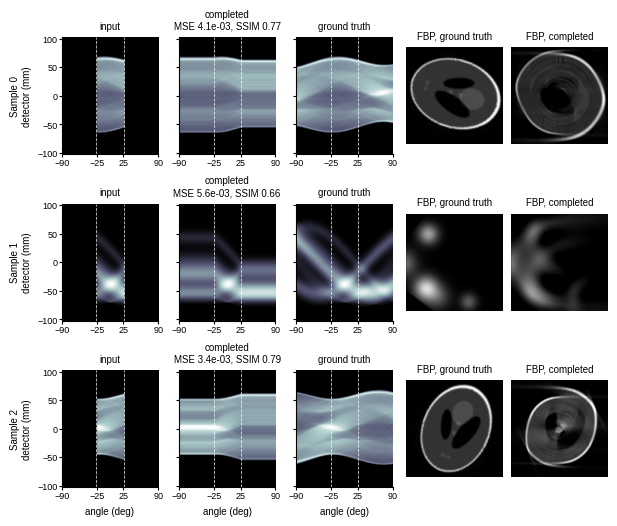

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (218 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


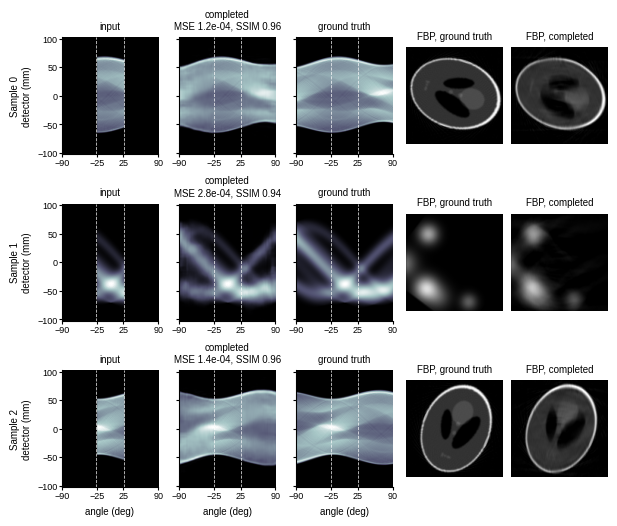

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (218 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


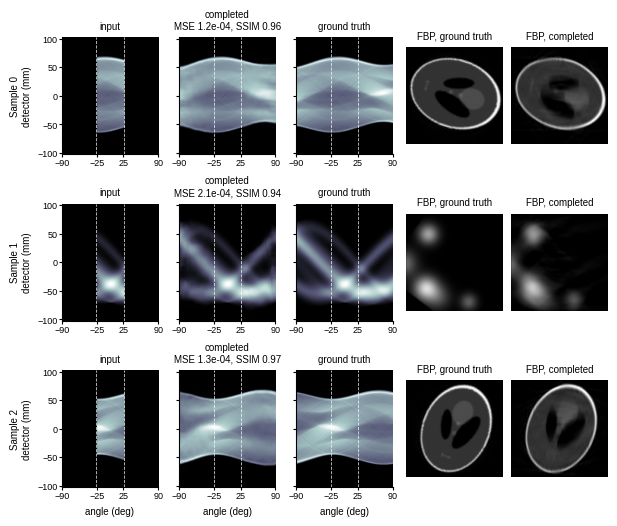

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (218 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


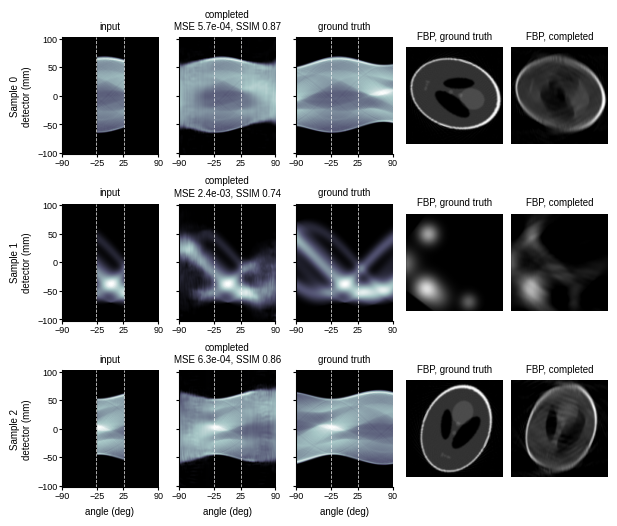

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (218 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


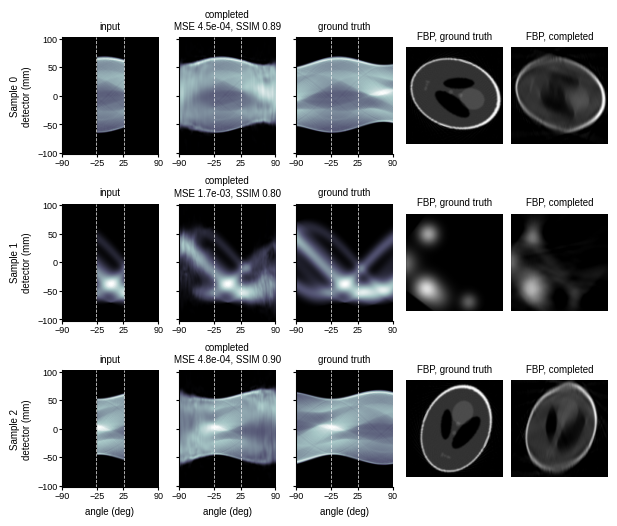

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (274 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


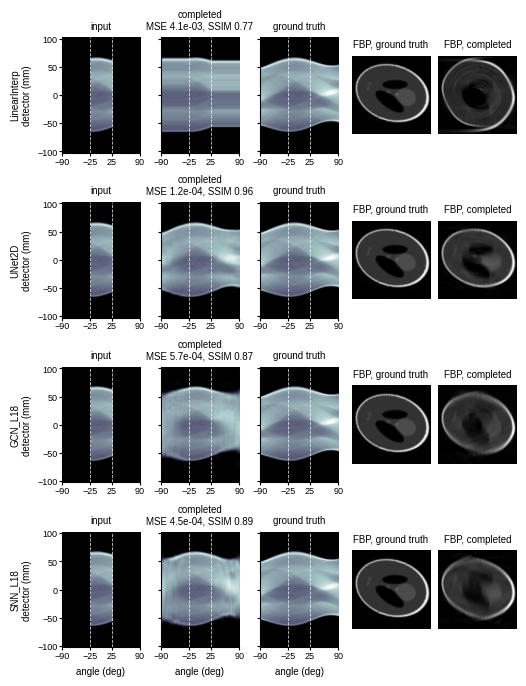

The per-sample metrics match the CSV.


In [6]:
@torch.no_grad()
def complete(model, incomplete: torch.Tensor) -> np.ndarray:
    """Every model, learned or not, shares the interface [B, 1, V, D] -> [B, 1, V, D]."""
    return model(incomplete.unsqueeze(0).to(device))[0, 0].float().cpu().numpy()


def fbp(sinogram: np.ndarray) -> np.ndarray:
    """FBP of a normalised sinogram, in the units of the phantom (as in src/evaluate.py)."""
    return fbp_reconstruction(sinogram * geometry_config.sino_norm, geometry_config)


samples = [dataset[i] for i in range(NUM_VIZ_SAMPLES)]
ground_truth_fbp = [fbp(full[0].numpy()) for _, full, _ in samples]
stale = set()
SAMPLE0_MODELS = ["LinearInterp", "UNet2D", "GCN_L18", "SNN_L18"]  # Figure "Test sample 0 completed by four models"


def draw_row(axes_row, incomplete, full, pred_np, m, truth_fbp, row_label):
    """One row: input | completed sinogram | ground truth | FBP of the ground truth | FBP of the completion."""
    inc_np, full_np = incomplete[0].numpy(), full[0].numpy()
    sinograms = [(inc_np, "input"),
                 (pred_np, f"completed\nMSE {m['mse_wedge']:.1e}, SSIM {m['ssim_wedge']:.2f}"),
                 (full_np, "ground truth")]
    for ax, (sino, title) in zip(axes_row[:3], sinograms):
        ax.imshow(sino.T, cmap="bone", origin="lower", aspect="auto", extent=sino_extent, vmin=0.0, vmax=full_np.max())
        for edge in window_edges:
            ax.axvline(edge, color="white", alpha=0.8, linestyle="--", linewidth=0.6)
        ax.set_title(title, fontsize=7)
        ax.set_xticks([-90, -25, 25, 90])
        ax.tick_params(length=2, pad=1, labelsize=6.5)
    for ax in axes_row[1:3]:
        ax.set_yticklabels([])
    axes_row[0].set_ylabel(f"{row_label}\ndetector (mm)", fontsize=7)
    for ax, (image, title) in zip(axes_row[3:], [(truth_fbp, "FBP, ground truth"), (fbp(pred_np), "FBP, completed")]):
        ax.imshow(image, cmap="gray", origin="lower", extent=image_extent, vmin=0.0, vmax=1.0)
        ax.set_title(title, fontsize=7)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)


def new_figure(n_rows, width=1.0):
    """width: fraction of the text width at which the thesis includes the figure."""
    fig, axes = plt.subplots(n_rows, 5, figsize=(width * THESIS_W, 1.6 * n_rows + 0.35), squeeze=False, layout="constrained")
    for ax in axes[-1, :3]:
        ax.set_xlabel("angle (deg)", fontsize=7)
    return fig, axes


for name in [m for m in VIZ_MODELS if m in models]:
    fig, axes = new_figure(NUM_VIZ_SAMPLES)
    for i, (incomplete, full, _) in enumerate(samples):
        pred_np = complete(models[name], incomplete)
        m = sinogram_metrics(pred_np, full[0].numpy(), missing_views)
        csv_row = results[(results["Sample"] == i) & (results["Model"] == name)]
        if not csv_row.empty and not np.isclose(csv_row["mse_wedge"].iloc[0], m["mse_wedge"], rtol=1e-3):
            stale.add(name)
        draw_row(axes[i], incomplete, full, pred_np, m, ground_truth_fbp[i], f"Sample {i}")
    fig.savefig(FIG_DIR / f"qualitative_{name}.png", dpi=300)
    plt.show()

present0 = [name for name in SAMPLE0_MODELS if name in models]
if present0:
    incomplete, full, _ = samples[0]
    fig, axes = new_figure(len(present0), width=0.85)  # included at 0.85\linewidth
    for row, name in enumerate(present0):
        pred_np = complete(models[name], incomplete)
        m = sinogram_metrics(pred_np, full[0].numpy(), missing_views)
        draw_row(axes[row], incomplete, full, pred_np, m, ground_truth_fbp[0], name)
    fig.savefig(FIG_DIR / "qualitative_sample0.png", dpi=300)
    plt.show()

if stale:
    print(f"WARNING: the CSV does not match the current checkpoints of {sorted(stale)}: re-run python -m src.evaluate.")
else:
    print("The per-sample metrics match the CSV.")

## 3. Angular reach of the graph models

x axis: angular distance $d$ between a missing view and the acquired window (both sides of the wedge folded together).
A graph model with $L$ layers and $k$ neighbours per view cannot receive any measurement at $d > L \cdot k/2$ views
($6L$ degrees for $k = 12$): its output there is **identical for every sample**, so its per-view MSE cannot go below the
**floor**, the inter-sample variance of the ground truth (the error of the best prediction that ignores the measurements).

- Left: per-view MSE and floor. Right: $\rho(d)$ = std over the samples of the prediction / std over the samples of the
  ground truth, i.e. the share of the real variability that the model reproduces (exactly 0 beyond the reach).
- Colour = model family (as in section 1), line style = depth (solid: 6 layers, dashed: 12, dotted: 18).
- The table checks the theorem on the trained models: beyond the reach, the inter-sample std of the prediction must be
  0 (up to float32 rounding on the GPU: ρ ≤ 1e-5) and MSE / floor must be ≥ 1. The references (U-Net, interpolation) are split at the reach of 6 layers, as a control.
- Only the raw graph models are checked: a `_P4` model adds the moment regression, fitted on the acquired views, so
  beyond the reach it does depend on the measurements (section 3 bis).

In [7]:
from src.checkpoint import load_checkpoint
from src.models.factory import GRAPH_MODELS
from src.models.view_graph.graph import angular_reach_deg

PROTOCOL_K, PROTOCOL_DEPTHS = 12, (6, 12, 18)
DEPTH_STYLES = {6: "-", 12: "--", 18: ":"}
REFERENCE_MODELS = ["UNet2D", "LinearInterp"]

geometry_config = GeometryConfig()
step = geometry_config.angle_step_deg
per_view_mse = pd.read_csv(EVAL_DIR / "per_view_mse.csv")
var_path = EVAL_DIR / "per_view_var.csv"
per_view_var = pd.read_csv(var_path) if var_path.exists() else None
if per_view_var is None:
    print(f"{var_path} is missing: re-run python -m src.evaluate to get the floor and the right panel.")

# Angular distance of every missing view to the acquired window, on the grid of the angular step.
view_angles = per_view_mse["angle_deg"].to_numpy()
wedge = ~per_view_mse["acquired"].to_numpy(dtype=bool)
distance_deg = np.maximum(geometry_config.angle_min_deg - view_angles, view_angles - geometry_config.angle_max_deg)
wedge_distance = np.rint(distance_deg[wedge] / step) * step


def fold(per_view_values) -> pd.Series:
    """Mean of a per-view quantity over the missing views at the same distance to the window."""
    return pd.Series(np.asarray(per_view_values)[wedge]).groupby(wedge_distance).mean()


def depth(model_name: str):
    return parse_model_name(model_name)[1].get("num_layers")


def reach_deg(model_name: str) -> float:
    """Angular reach of a trained graph model, from the configuration stored in its checkpoint."""
    config = load_checkpoint(CHECKPOINT_DIR / run_name_of(model_name) / "best_model.pt")["model_config"]
    return angular_reach_deg(config["num_layers"], config["k"], step, config.get("graph_type", "knn"))


model_columns = [c for c in per_view_mse.columns if c not in ("angle_deg", "acquired")]
graph_models = [m for m in model_columns if parse_model_name(m)[0] in GRAPH_MODELS and not is_projected(m)
                and not is_replica(m) and not is_budget_or_graph_variant(m)]
projected_graph_models = [m for m in model_columns
                          if parse_model_name(m)[0] in GRAPH_MODELS and is_projected(m) and not is_replica(m)
                          and not is_budget_or_graph_variant(m)]
references = [m for m in REFERENCE_MODELS if m in model_columns]
floor = fold(per_view_var["GroundTruth"]) if per_view_var is not None else None
print(f"Graph models: {graph_models or 'none evaluated yet'} | references: {references}")

Graph models: ['GCN_L6', 'GCN_L12', 'GCN_L18', 'SNN_L6', 'SNN_L12', 'SNN_L18'] | references: ['UNet2D', 'LinearInterp']


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (224 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


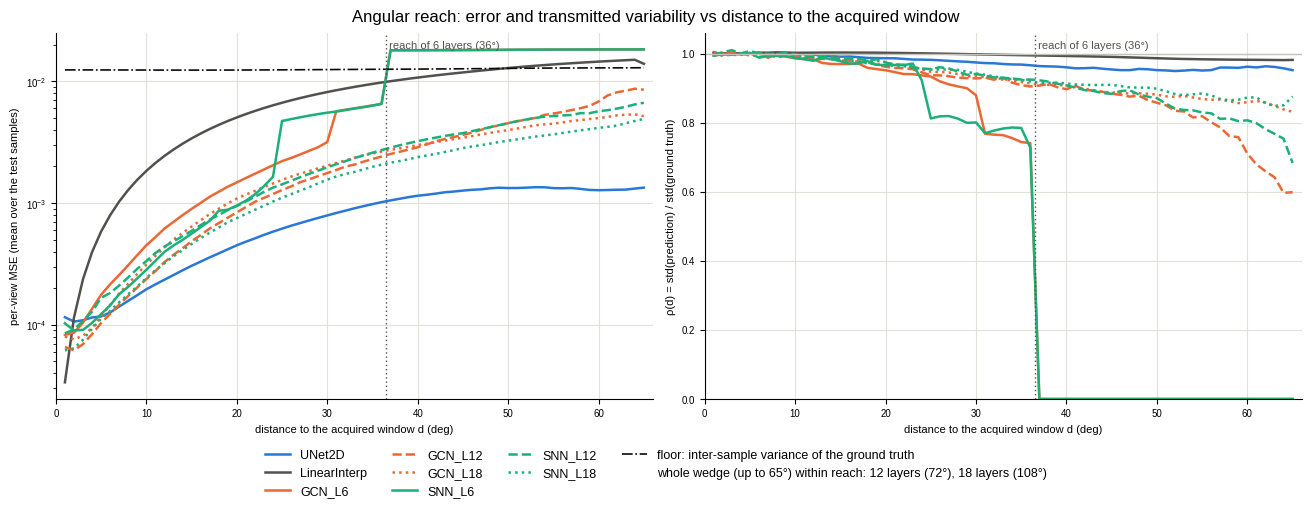

In [8]:
from matplotlib.lines import Line2D

fig, (ax_mse, ax_rho) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for name in references + graph_models:
    style = {"color": FAMILY_COLORS.get(family(name), "#898781"), "linestyle": DEPTH_STYLES.get(depth(name), "-"),
             "linewidth": 1.8, "label": name}
    curve = fold(per_view_mse[name])
    ax_mse.plot(curve.index, curve.to_numpy(), **style)
    if per_view_var is not None:
        rho = np.sqrt(fold(per_view_var[name]) / floor)
        ax_rho.plot(rho.index, rho.to_numpy(), **style)
if floor is not None:
    ax_mse.plot(floor.index, floor.to_numpy(), color="#0b0b0b", linestyle="-.", linewidth=1.2,
                label="floor: inter-sample variance of the ground truth")

# Reach of the protocol depths: a vertical line between the last reachable view and the next one.
d_max = wedge_distance.max()
covering = []
for L in PROTOCOL_DEPTHS:
    reach = angular_reach_deg(L, PROTOCOL_K, step)
    if reach >= d_max:
        covering.append(f"{L} layers ({reach:.0f}°)")
        continue
    for ax in (ax_mse, ax_rho):
        ax.axvline(reach + step / 2, color="#52514e", linewidth=1.0, linestyle=(0, (1, 2)))
        ax.text(reach + step / 2, 0.98, f" reach of {L} layers ({reach:.0f}°)", transform=ax.get_xaxis_transform(),
                va="top", fontsize=8, color="#52514e")
ax_mse.set_yscale("log")
ax_mse.set_ylabel("per-view MSE (mean over the test samples)")
ax_rho.set_ylabel("ρ(d) = std(prediction) / std(ground truth)")
ax_rho.axhline(1.0, color="#c3c2b7", linewidth=1.0)
ax_rho.set_ylim(bottom=0.0)
for ax in (ax_mse, ax_rho):
    ax.set_xlabel("distance to the acquired window d (deg)")
    ax.set_xlim(0.0, d_max + step)
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
handles, labels = ax_mse.get_legend_handles_labels()
if covering:  # text-only legend entry
    handles.append(Line2D([], [], linestyle="none"))
    labels.append(f"whole wedge (up to {d_max:.0f}°) within reach: " + ", ".join(covering))
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False, fontsize=9)
fig.suptitle("Angular reach: error and transmitted variability vs distance to the acquired window", fontsize=12)
fig.savefig(FIG_DIR / "angular_reach.pdf", bbox_inches="tight")
plt.show()

In [9]:
STD_COL, RATIO_COL = "max std beyond (theory: 0)", "min MSE / floor beyond (theory: ≥ 1)"
RHO_COL = "max ρ beyond (theory: 0)"
# float32 rounding on the GPU: the FFT of the shift transport leaves ρ ~ 1e-8 (exactly 0 on the CPU, see
# tests/test_graph_models.py); information from the measurements would give ρ of order 1e-2 or more.
ROUNDING_RHO = 1e-5
l6_reach = angular_reach_deg(PROTOCOL_DEPTHS[0], PROTOCOL_K, step)
rows = []
for name in graph_models + references:
    split = reach_deg(name) if name in graph_models else l6_reach
    beyond = wedge_distance > split
    mse_views = per_view_mse[name].to_numpy()[wedge]
    row = {"Model": name, "split at d (deg)": split,
           "views beyond": f"{beyond.sum()} / {wedge.sum()} ({beyond.mean():.0%})",
           "MSE within reach": mse_views[~beyond].mean() if (~beyond).any() else np.nan,
           "MSE beyond reach": mse_views[beyond].mean() if beyond.any() else np.nan}
    if name in graph_models and per_view_var is not None and beyond.any():
        pred_var = per_view_var[name].to_numpy()[wedge][beyond]
        gt_var = per_view_var["GroundTruth"].to_numpy()[wedge][beyond]
        row[STD_COL] = np.sqrt(pred_var.max())
        row[RHO_COL] = np.sqrt(pred_var / gt_var).max()
        row[RATIO_COL] = (mse_views[beyond] / gt_var).min()
    rows.append(row)

if rows:
    reach_table = pd.DataFrame(rows).set_index("Model")
    display(reach_table)
    export_table(reach_table, "angular_reach")
    if STD_COL in reach_table:
        for name, row in reach_table.dropna(subset=[STD_COL]).iterrows():
            holds = row[RHO_COL] <= ROUNDING_RHO and row[RATIO_COL] >= 1.0 - 1e-9
            rounding = f" (up to float32 rounding, ρ ≤ {row[RHO_COL]:.0e})" if row[STD_COL] > 0 else ""
            verdict = (f"identical for every sample{rounding} and above the floor: theorem verified" if holds
                       else "NOT independent of the measurements: check the model and the evaluation")
            print(f"{name}: beyond {row['split at d (deg)']:.0f}°, the output is {verdict}.")
else:
    print("Nothing to check yet: evaluate the models first (python -m src.evaluate).")

,split at d (deg),views beyond,MSE within reach,MSE beyond reach,max std beyond (theory: 0),max ρ beyond (theory: 0),min MSE / floor beyond (theory: ≥ 1)
Model,,,,,,,
GCN_L6,36.0,57 / 129 (44%),0.001987,0.018149,0.000000e+00,0.000000e+00,1.394116
GCN_L12,72.0,0 / 129 (0%),0.002699,NaN,NaN,NaN,NaN
GCN_L18,108.0,0 / 129 (0%),0.002399,NaN,NaN,NaN,NaN
SNN_L6,36.0,57 / 129 (44%),0.002231,0.018155,6.707611e-08,5.882535e-07,1.394805
SNN_L12,72.0,0 / 129 (0%),0.002609,NaN,NaN,NaN,NaN
SNN_L18,108.0,0 / 129 (0%),0.001926,NaN,NaN,NaN,NaN
UNet2D,36.0,57 / 129 (44%),0.000458,0.001268,NaN,NaN,NaN
LinearInterp,36.0,57 / 129 (44%),0.004621,0.012820,NaN,NaN,NaN


GCN_L6: beyond 36°, the output is identical for every sample and above the floor: theorem verified.
SNN_L6: beyond 36°, the output is identical for every sample (up to float32 rounding, ρ ≤ 6e-07) and above the floor: theorem verified.


## 3 bis. Graph models followed by the HLCC moment regression (P4)

`<model>_P4` is the completed sinogram of the model whose moments of orders 0 to 4 on the missing views are replaced by
their harmonic extension fitted on the acquired views (Huang et al. 2017, `src/hlcc.py`, no training). The
regression reads **only the acquired views**, so beyond the reach of a graph model it brings information from the
measurements back: $\rho(d)$ is no longer 0 and the error is no longer bounded by the floor. It fixes about 15 numbers
per sinogram, so the gain beyond the reach measures how much of the error
there is low-order.

One column per depth. Top: per-view MSE (log scale) and floor. Bottom: $\rho(d)$. Raw model: solid line, colour of its
family; with the regression: dashed violet line.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (290 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


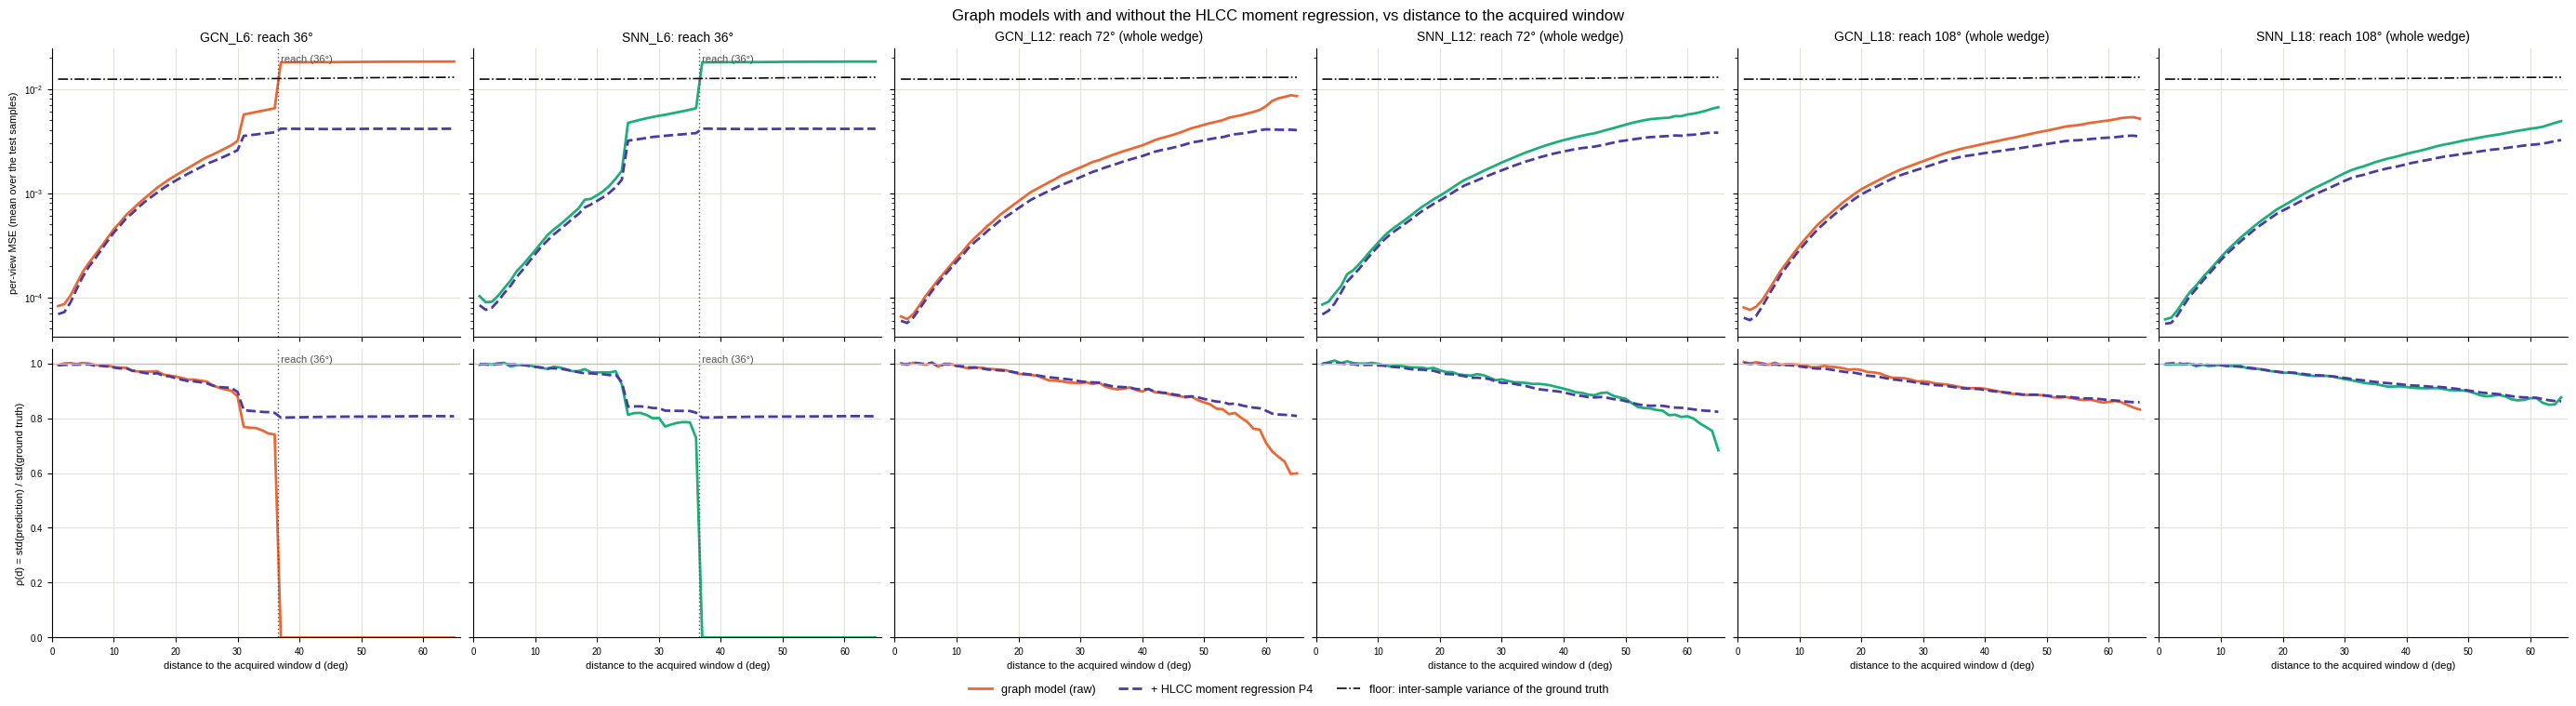

,MSE wedge,MSE within reach,MSE beyond reach,MSE / floor beyond,ρ beyond
Model,,,,,
GCN_L6,0.00913,0.00199,0.0181,1.42,0
GCN_L6_P4,0.00264,0.00146,0.00414,0.324,0.805
SNN_L6,0.00927,0.00223,0.0182,1.42,1.03e-08
SNN_L6_P4,0.00266,0.00148,0.00414,0.324,0.805
GCN_L12,0.0027,0.0027,NaN,NaN,NaN
GCN_L12_P4,0.00184,0.00184,NaN,NaN,NaN
SNN_L12,0.00261,0.00261,NaN,NaN,NaN
SNN_L12_P4,0.00189,0.00189,NaN,NaN,NaN
GCN_L18,0.0024,0.0024,NaN,NaN,NaN


In [10]:
P4_COLOR = "#4a3aa7"  # violet, darker than every family colour: the raw / projected pair also differs by lightness
p4_pairs = sorted(((unprojected(m), m) for m in projected_graph_models if unprojected(m) in graph_models),
                  key=lambda pair: depth(pair[0]))

if not p4_pairs:
    print("No graph model evaluated with its _P4 variant: run python -m src.evaluate --models GCN_L6 GCN_L6_P4.")
else:
    fig, axes = plt.subplots(2, len(p4_pairs), figsize=(4.6 * len(p4_pairs), 7.5), squeeze=False,
                             sharex=True, sharey="row", layout="constrained")
    for col, (raw, projected) in enumerate(p4_pairs):
        ax_mse, ax_rho = axes[0, col], axes[1, col]
        for name, color, linestyle, label in ((raw, FAMILY_COLORS.get(family(raw), "#898781"), "-", "graph model (raw)"),
                                              (projected, P4_COLOR, "--", "+ HLCC moment regression P4")):
            curve = fold(per_view_mse[name])
            ax_mse.plot(curve.index, curve.to_numpy(), color=color, linestyle=linestyle, linewidth=2.0, label=label)
            if per_view_var is not None:
                rho = np.sqrt(fold(per_view_var[name]) / floor)
                ax_rho.plot(rho.index, rho.to_numpy(), color=color, linestyle=linestyle, linewidth=2.0, label=label)
        if floor is not None:
            ax_mse.plot(floor.index, floor.to_numpy(), color="#0b0b0b", linestyle="-.", linewidth=1.2,
                        label="floor: inter-sample variance of the ground truth")
        reach = reach_deg(raw)
        if reach < d_max:
            for ax in (ax_mse, ax_rho):
                ax.axvline(reach + step / 2, color="#52514e", linewidth=1.0, linestyle=(0, (1, 2)))
                ax.text(reach + step / 2, 0.98, f" reach ({reach:.0f}°)", transform=ax.get_xaxis_transform(),
                        va="top", fontsize=8, color="#52514e")
        ax_mse.set_title(f"{raw}: reach {reach:.0f}°" + (" (whole wedge)" if reach >= d_max else ""), fontsize=10)
        ax_mse.set_yscale("log")
        ax_rho.axhline(1.0, color="#c3c2b7", linewidth=1.0)
        ax_rho.set_ylim(bottom=0.0)
        ax_rho.set_xlabel("distance to the acquired window d (deg)")
        for ax in (ax_mse, ax_rho):
            ax.set_xlim(0.0, d_max + step)
            ax.grid(color="#e1e0d9", linewidth=0.8)
            ax.set_axisbelow(True)
    axes[0, 0].set_ylabel("per-view MSE (mean over the test samples)")
    axes[1, 0].set_ylabel("ρ(d) = std(prediction) / std(ground truth)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False, fontsize=9)
    fig.suptitle("Graph models with and without the HLCC moment regression, vs distance to the acquired window", fontsize=12)
    fig.savefig(FIG_DIR / "angular_reach_p4.pdf", bbox_inches="tight")
    plt.show()

    rows = []
    gt_var = per_view_var["GroundTruth"].to_numpy()[wedge] if per_view_var is not None else None
    for raw, projected in p4_pairs:
        beyond = wedge_distance > reach_deg(raw)
        for name in (raw, projected):
            mse_views = per_view_mse[name].to_numpy()[wedge]
            row = {"Model": name, "MSE wedge": mse_views.mean(), "MSE within reach": mse_views[~beyond].mean(),
                   "MSE beyond reach": mse_views[beyond].mean() if beyond.any() else np.nan}
            if gt_var is not None and beyond.any():
                row["MSE / floor beyond"] = (mse_views[beyond] / gt_var[beyond]).mean()
                row["ρ beyond"] = np.sqrt(per_view_var[name].to_numpy()[wedge][beyond] / gt_var[beyond]).mean()
            rows.append(row)
    p4_reach_table = pd.DataFrame(rows).set_index("Model")
    with pd.option_context("display.float_format", "{:.3g}".format):
        display(p4_reach_table)
    export_table(p4_reach_table, "angular_reach_p4")


## 4. Oversmoothing: GCN vs SNN at 12 and 18 layers

The SNN is the shift-transport model, trained with the Optuna configuration of the GCN of the same depth: the two
models differ only by their restriction maps. The criterion compares the seed-0 runs; section 4 bis measures how much
a run of the same architecture changes with another seed.

At 12 and 18 layers the whole wedge is within reach (72° and 108° > 65°), so a washed-out wedge can no longer come from
the reach: it is the signature of the diffusion itself. At 6 layers the grey band beyond 36° exists for **both** models
and is the reach effect of section 3: that depth is shown but stays out of the criterion.

1. Qualitative: sinograms, error maps (common scale per row) and FBP on test samples fixed before looking at the
   results (`OVERSMOOTHING_SAMPLES`).
2. Angular profiles $p(\theta, s_0)$ at a few detector positions: is the sinusoidal trace continued or flattened?
3. Per test sample (`src/evaluate.py`): `mse_wedge` and the Dirichlet-energy ratios prediction / ground truth on the
   wedge, along the angle and along the detector (1: as much variation as the ground truth, < 1: smoother).
4. Criterion fixed before the test evaluation: the SNN beats the GCN at 12 **and** 18 layers, on `mse_wedge`
   **and** on the angular ratio (closer to 1, i.e. smaller $|\log \text{ratio}|$), each with a paired Wilcoxon test
   p < 0.05 on the same test samples.

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (450 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


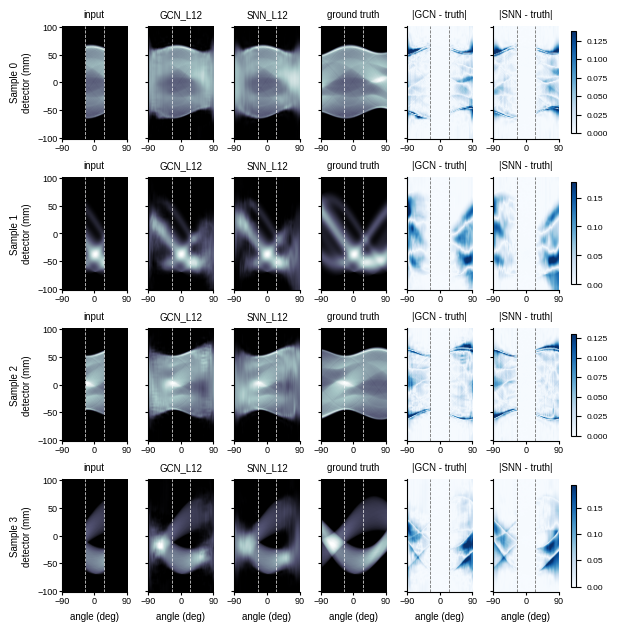

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (62 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


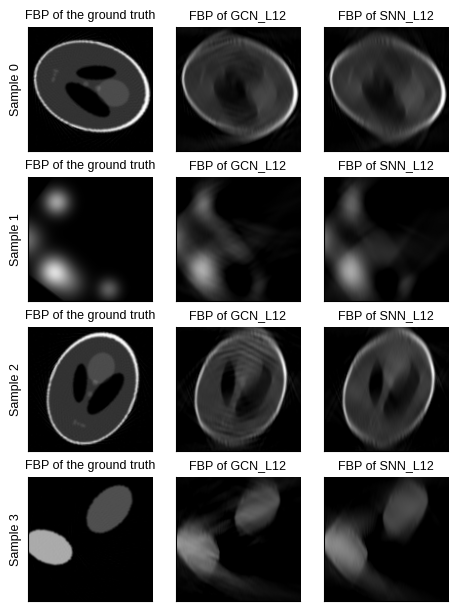

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (474 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


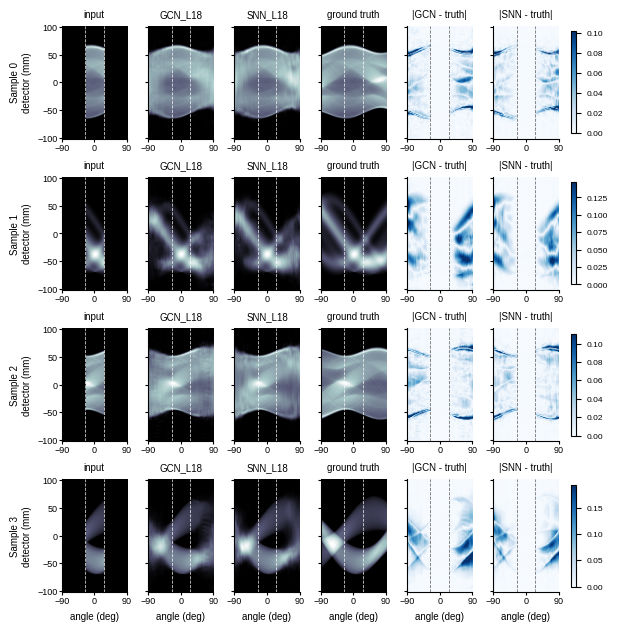

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (62 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


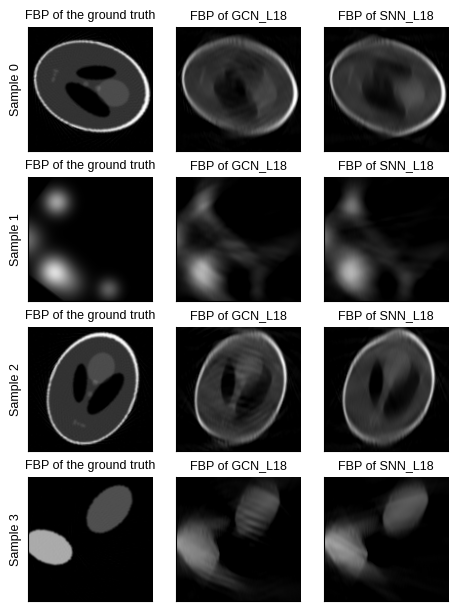

In [11]:
from scipy.stats import wilcoxon

OVERSMOOTHING_DEPTHS = (12, 18)       # the whole wedge is within reach (72° and 108° > 65°)
OVERSMOOTHING_SAMPLES = [0, 1, 2, 3]  # test samples fixed before looking at the results
PROFILE_DETECTORS = [40, 64, 88]      # detector pixels of the angular profiles
ALPHA = 0.05                          # level of the paired Wilcoxon tests

pairs = {L: (f"GCN_L{L}", f"SNN_L{L}") for L in OVERSMOOTHING_DEPTHS if f"GCN_L{L}" in models and f"SNN_L{L}" in models}
if not pairs:
    print("No GCN / SNN pair at 12 or 18 layers is loaded: the figures of this section are skipped.")
else:
    dataset_4 = SinogramCompletionDataset(max(OVERSMOOTHING_SAMPLES) + 1, split="test", noise_level=NOISE_LEVEL,
                                          geometry_config=geometry_config)
    samples_4 = {i: dataset_4[i] for i in OVERSMOOTHING_SAMPLES}
    predictions_4 = {(name, i): complete(models[name], samples_4[i][0])
                     for pair in pairs.values() for name in pair for i in OVERSMOOTHING_SAMPLES}

for L, (gcn, snn) in pairs.items():
    n_rows = len(OVERSMOOTHING_SAMPLES)
    fig, axes = plt.subplots(n_rows, 6, figsize=(THESIS_W, 1.45 * n_rows + 0.4), squeeze=False, layout="constrained")
    for row, i in enumerate(OVERSMOOTHING_SAMPLES):
        incomplete, full, _ = samples_4[i]
        full_np = full[0].numpy()
        errors = {name: np.abs(predictions_4[(name, i)] - full_np) for name in (gcn, snn)}
        error_max = max(1e-6, *(np.percentile(e[missing_views], 99) for e in errors.values()))
        panels = [(incomplete[0].numpy(), "input", "bone", full_np.max()),
                  (predictions_4[(gcn, i)], gcn, "bone", full_np.max()),
                  (predictions_4[(snn, i)], snn, "bone", full_np.max()),
                  (full_np, "ground truth", "bone", full_np.max()),
                  (errors[gcn], "|GCN - truth|", "Blues", error_max),
                  (errors[snn], "|SNN - truth|", "Blues", error_max)]
        for ax, (image, title, cmap, vmax) in zip(axes[row], panels):
            shown = ax.imshow(image.T, cmap=cmap, origin="lower", aspect="auto", extent=sino_extent, vmin=0.0, vmax=vmax)
            for edge in window_edges:
                ax.axvline(edge, color="white" if cmap == "bone" else "#52514e", alpha=0.8, linestyle="--", linewidth=0.6)
            ax.set_title(title, fontsize=7)
            ax.set_xticks([-90, 0, 90])
            ax.tick_params(length=2, pad=1, labelsize=6.5)
            if ax is not axes[row, 0]:
                ax.set_yticklabels([])
        colorbar = fig.colorbar(shown, ax=axes[row, 4:].tolist(), shrink=0.9)
        colorbar.ax.tick_params(labelsize=6)
        axes[row, 0].set_ylabel(f"Sample {i}\ndetector (mm)", fontsize=7)
    for ax in axes[-1]:
        ax.set_xlabel("angle (deg)", fontsize=7)
    fig.savefig(FIG_DIR / f"oversmoothing_sinograms_L{L}.pdf", bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(n_rows, 3, figsize=(0.75 * THESIS_W, 1.45 * n_rows + 0.2), squeeze=False, layout="constrained")
    for row, i in enumerate(OVERSMOOTHING_SAMPLES):
        sinograms = [(samples_4[i][1][0].numpy(), "FBP of the ground truth"),
                     (predictions_4[(gcn, i)], f"FBP of {gcn}"), (predictions_4[(snn, i)], f"FBP of {snn}")]
        for ax, (sinogram, title) in zip(axes[row], sinograms):
            ax.imshow(fbp(sinogram), cmap="gray", origin="lower", extent=image_extent, vmin=0.0, vmax=1.0)
            ax.set_title(title, fontsize=9)
            ax.set_xticks([])
            ax.set_yticks([])
        axes[row, 0].set_ylabel(f"Sample {i}", fontsize=9)
    fig.savefig(FIG_DIR / f"oversmoothing_fbp_L{L}.pdf", bbox_inches="tight")
    plt.show()

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (243 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


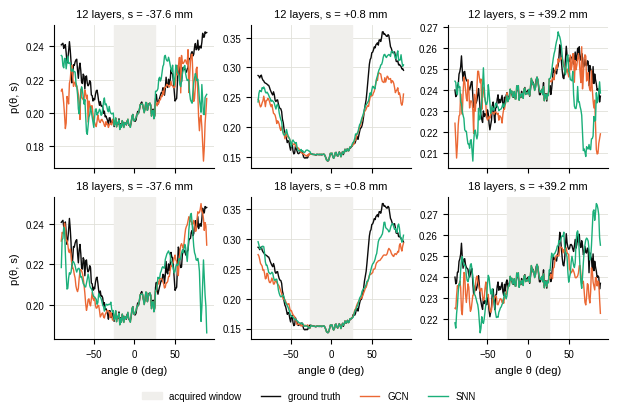

In [12]:
if pairs:
    profile_sample = OVERSMOOTHING_SAMPLES[0]
    truth = samples_4[profile_sample][1][0].numpy()
    fig, axes = plt.subplots(len(pairs), len(PROFILE_DETECTORS), figsize=(THESIS_W, 1.75 * len(pairs) + 0.5),
                             squeeze=False, sharex=True, layout="constrained")
    for row, (L, (gcn, snn)) in enumerate(pairs.items()):
        for col, pixel in enumerate(PROFILE_DETECTORS):
            ax = axes[row, col]
            ax.axvspan(*window_edges, color="#f0efec", label="acquired window")
            ax.plot(angles_deg, truth[:, pixel], color="#0b0b0b", linewidth=1.0, label="ground truth")
            ax.plot(angles_deg, predictions_4[(gcn, profile_sample)][:, pixel], color=FAMILY_COLORS["GCN"], linewidth=1.0, label="GCN")
            ax.plot(angles_deg, predictions_4[(snn, profile_sample)][:, pixel], color=FAMILY_COLORS["SNN"], linewidth=1.0, label="SNN")
            s_mm = (pixel - geometry_config.det_col_count / 2 + 0.5) * geometry_config.det_pixel_size_mm
            ax.set_title(f"{L} layers, s = {s_mm:+.1f} mm")
            ax.grid(color="#e1e0d9", linewidth=0.6)
            ax.set_axisbelow(True)
        axes[row, 0].set_ylabel("p(θ, s)")
    for ax in axes[-1]:
        ax.set_xlabel("angle θ (deg)")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
    fig.savefig(FIG_DIR / "oversmoothing_profiles.pdf", bbox_inches="tight")
    plt.show()

,Status,GCN mse_wedge,SNN mse_wedge,SNN vs GCN [95 % CI],SNN better (samples),p mse_wedge,GCN angle ratio,SNN angle ratio,p |log angle ratio|,GCN detector ratio,SNN detector ratio
layers,,,,,,,,,,,
6,exploratory (reach-limited),0.009128,0.009267,"+1.5 % [+1.1, +1.9]",25%,2.925461e-16,11.849873,11.921643,3.032245e-13,0.278394,0.264413
12,confirmatory (pre-registered),0.002699,0.002609,"-3.3 % [-8.2, +1.8]",54%,2.580139e-01,3.219657,1.420553,7.106057e-18,0.487612,0.395583
18,confirmatory (pre-registered),0.002399,0.001926,"-19.7 % [-24.1, -15.0]",83%,1.122947e-21,1.138974,1.230868,5.393834e-01,0.446242,0.477574


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (105 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


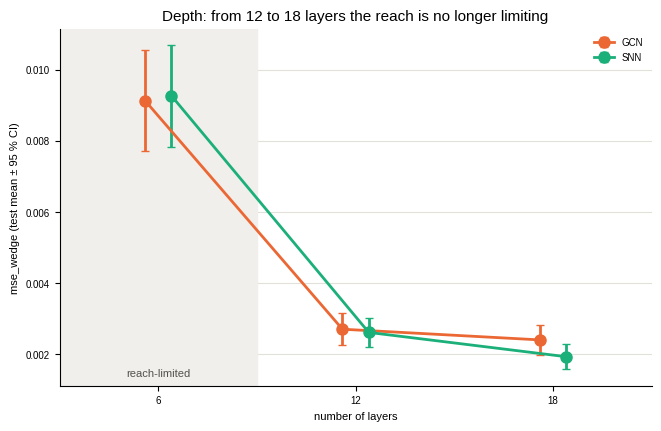

In [13]:
SMOOTHNESS_COLS = ["dirichlet_angle_ratio", "dirichlet_detector_ratio"]


def paired_wilcoxon(differences: pd.Series) -> float:
    """Two-sided p-value of the paired Wilcoxon signed-rank test (NaN if all differences are 0)."""
    try:
        return float(wilcoxon(differences).pvalue)
    except ValueError:
        return float("nan")


evaluated = set(results["Model"])
if not set(SMOOTHNESS_COLS) <= set(results.columns):
    print("The CSV has no Dirichlet-energy ratios: re-run python -m src.evaluate.")
else:
    by_sample = {m: results[results["Model"] == m].set_index("Sample").sort_index() for m in evaluated}
    rows, verdicts = [], {}
    for L in PROTOCOL_DEPTHS:
        gcn, snn = f"GCN_L{L}", f"SNN_L{L}"
        if gcn not in evaluated or snn not in evaluated:
            continue
        a, b = by_sample[gcn].align(by_sample[snn], join="inner", axis=0)
        mse_diff = b["mse_wedge"] - a["mse_wedge"]  # < 0: the SNN is better
        angle_gap = np.abs(np.log(b["dirichlet_angle_ratio"])) - np.abs(np.log(a["dirichlet_angle_ratio"]))  # < 0: SNN closer to 1
        mse_p, angle_p = paired_wilcoxon(mse_diff), paired_wilcoxon(angle_gap)
        if L in OVERSMOOTHING_DEPTHS:
            verdicts[L] = {"mse_wedge": bool(np.median(mse_diff) < 0 and mse_p < ALPHA),
                           "|log angle ratio|": bool(np.median(angle_gap) < 0 and angle_p < ALPHA)}
        rows.append({
            "layers": L,
            "Status": "confirmatory (pre-registered)" if L in OVERSMOOTHING_DEPTHS else "exploratory (reach-limited)",
            "GCN mse_wedge": a["mse_wedge"].mean(), "SNN mse_wedge": b["mse_wedge"].mean(),
            "SNN vs GCN [95 % CI]": format_change(paired_bootstrap(b["mse_wedge"].to_numpy(), a["mse_wedge"].to_numpy())),
            "SNN better (samples)": f"{(mse_diff < 0).mean():.0%}", "p mse_wedge": mse_p,
            "GCN angle ratio": a["dirichlet_angle_ratio"].mean(), "SNN angle ratio": b["dirichlet_angle_ratio"].mean(),
            "p |log angle ratio|": angle_p,
            "GCN detector ratio": a["dirichlet_detector_ratio"].mean(), "SNN detector ratio": b["dirichlet_detector_ratio"].mean(),
        })
    if rows:
        comparison_table = pd.DataFrame(rows).set_index("layers")
        display(comparison_table)
        export_table(comparison_table, "gcn_vs_snn")

    print("Confirmatory test: the criterion requires all four tests (2 depths x 2 metrics) at p < 0.05 "
          "(intersection-union test), so no multiplicity correction applies.")
    if len(verdicts) < len(OVERSMOOTHING_DEPTHS):
        print("The criterion needs GCN and SNN at 12 and 18 layers in the CSV.")
    elif all(all(tests.values()) for tests in verdicts.values()):
        print("Criterion MET at 12 and 18 layers: the shift transport limits the dilution of the information along the angle.")
    else:
        failed = "; ".join(f"{L} layers: SNN not significantly better on {', '.join(m for m, ok in tests.items() if not ok)}"
                           for L, tests in verdicts.items() if not all(tests.values()))
        print(f"Criterion NOT met ({failed}) for the pre-registered test. "
              "Any other difference in the table is exploratory.")

    depths_present = [L for L in PROTOCOL_DEPTHS if f"GCN_L{L}" in evaluated or f"SNN_L{L}" in evaluated]
    if depths_present:
        fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
        ax.axvspan(PROTOCOL_DEPTHS[0] - 3, (PROTOCOL_DEPTHS[0] + PROTOCOL_DEPTHS[1]) / 2, color="#f0efec")
        ax.text(PROTOCOL_DEPTHS[0], 0.02, "reach-limited", transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                fontsize=8, color="#52514e")
        for fam, dodge in (("GCN", -0.4), ("SNN", 0.4)):  # side by side, so that the error bars never hide each other
            present = [L for L in depths_present if f"{fam}_L{L}" in evaluated]
            if not present:
                continue
            values = [by_sample[f"{fam}_L{L}"]["mse_wedge"] for L in present]
            ax.errorbar([L + dodge for L in present], [v.mean() for v in values], yerr=[1.96 * v.sem() for v in values],
                        color=FAMILY_COLORS[fam], marker="o", markersize=8, linewidth=2, capsize=3, label=fam)
        ax.set_xticks(PROTOCOL_DEPTHS)
        ax.set_xlim(PROTOCOL_DEPTHS[0] - 3, PROTOCOL_DEPTHS[-1] + 3)
        ax.set_xlabel("number of layers")
        ax.set_ylabel("mse_wedge (test mean ± 95 % CI)")
        ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.legend(frameon=False)
        ax.set_title("Depth: from 12 to 18 layers the reach is no longer limiting", fontsize=11)
        fig.savefig(FIG_DIR / "oversmoothing_depth_trend.pdf", bbox_inches="tight")
        plt.show()

## 4 bis. Seeds: run-to-run noise

A replica `<run>_S<k>` is the same configuration trained with another seed (`launch_best_training.py --seed k`):
another initialisation and batch order, the same phantoms. The Wilcoxon tests of sections 1 to 4 pair the test
samples of two *trained networks*: they say whether one network is better than the other, not whether one
*architecture* is. Two networks of the same architecture already differ; a difference between architectures has to
exceed that run-to-run noise before it can be attributed to the architecture.

The U-Nets of the data study (section 5) have seeds 0, 1 and 2, the L18 graph models seeds 0 and 1. The seed-0
runs and the replicas were trained at two commits (9856b09 and af31110), but they run the same model code: the GCN
is numerically identical between the two, and the seed-0 SNN already used the shift transport committed in af31110.

- First table: test `mse_wedge` of every seed (with and without the moment regression).
- Second table: the same configuration with another seed (run-to-run noise), then SNN vs GCN for every seed and
  averaged over the seeds (per-sample mean of the seeds). Exploratory, Holm over the table.


In [14]:
def seed_of(model_name: str) -> int:
    """0, or k for a replica "<run>_S<k>"."""
    tags = [tag for tag in parse_full_model_name(model_name).tags if re.fullmatch(r"S\d+", tag)]
    return int(tags[0][1:]) if tags else 0


seed_groups = {}  # run of the seed 0 -> {seed: model name}
for name in trained_order:
    if is_replica(name) and re.sub(r"_S\d+", "", name) in per_sample:
        base = re.sub(r"_S\d+", "", name)
        seed_groups.setdefault(base, {0: base})[seed_of(name)] = name

if not seed_groups:
    print("No seed replica evaluated yet: python -m scripts.launch_best_training <study> --seed 1, then src.evaluate.")
else:
    rows = []
    for base, seeds in seed_groups.items():
        for seed, name in sorted(seeds.items()):
            projected = per_sample.get(f"{name}_P4")
            rows.append({"Run": base, "Seed": seed, "mse_wedge": f"{per_sample[name]['mse_wedge'].mean():.3e}",
                         "mse_wedge + P4": f"{projected['mse_wedge'].mean():.3e}" if projected is not None else "—",
                         "img_psnr": f"{per_sample[name]['img_psnr'].mean():.2f}"})
    seed_table = pd.DataFrame(rows).set_index(["Run", "Seed"])
    display(seed_table)
    export_table(seed_table, "seeds_metrics")

    rows, verdicts = [], []
    for base, seeds in seed_groups.items():
        for seed, name in sorted(seeds.items()):
            if seed:
                rows.append({"Comparison": f"{base}: seed {seed} vs seed 0 (same configuration)",
                             **paired_change(per_sample[base]["mse_wedge"], per_sample[name]["mse_wedge"])})
    for L in PROTOCOL_DEPTHS:
        gcn, snn = seed_groups.get(f"GCN_L{L}"), seed_groups.get(f"SNN_L{L}")
        if not gcn or not snn:
            continue
        common = sorted(set(gcn) & set(snn))
        changes = []
        for seed in common:
            change = paired_change(per_sample[gcn[seed]]["mse_wedge"], per_sample[snn[seed]]["mse_wedge"])
            rows.append({"Comparison": f"SNN_L{L} vs GCN_L{L}, seed {seed}", **change})
            changes.append(change["Change [95 % CI]"].split(" [")[0])
        averaged = [pd.concat([per_sample[family_seeds[s]]["mse_wedge"] for s in common], axis=1).mean(axis=1)
                    for family_seeds in (gcn, snn)]
        rows.append({"Comparison": f"SNN_L{L} vs GCN_L{L}, mean over seeds {common}", **paired_change(*averaged)})
        spreads = {fam: max(per_sample[n]["mse_wedge"].mean() for n in s.values()) /
                        min(per_sample[n]["mse_wedge"].mean() for n in s.values()) - 1
                   for fam, s in (("GCN", gcn), ("SNN", snn))}
        verdicts.append(f"{L} layers: SNN vs GCN = {', '.join(changes)} for the seeds {common}; between its seeds, "
                        f"the GCN changes by {spreads['GCN']:.0%} and the SNN by {spreads['SNN']:.0%}."
                        + (" The sign of the difference changes with the seed: no transport effect can be claimed."
                           if len({c.strip()[0] for c in changes}) > 1 else ""))
    comparison_seeds = with_holm(pd.DataFrame(rows).set_index("Comparison"))
    display(comparison_seeds)
    export_table(comparison_seeds, "seeds_comparisons")
    print("\n".join(verdicts))


mse_wedge mse_wedge + P4 img_psnr
Run             Seed                                   
UNet2dHLCC      0     8.173e-04      7.362e-04    23.43
                1     8.071e-04      7.357e-04    23.45
                2     8.445e-04      7.622e-04    23.28
UNet2D          0     8.154e-04      7.257e-04    23.35
                1     8.644e-04      7.780e-04    23.26
                2     8.882e-04      7.912e-04    23.33
GCN_L18         0     2.399e-03      1.838e-03    20.25
                1     1.661e-03      1.320e-03    21.39
SNN_L18         0     1.926e-03      1.470e-03    20.96
                1     1.793e-03      1.339e-03    21.10
UNet2D_N200     0     2.752e-03      2.014e-03    19.53
                1     2.525e-03      1.982e-03    19.61
                2     2.688e-03      1.993e-03    19.50
UNet2dHLCC_N200 0     2.712e-03      1.990e-03    19.55
                1     2.539e-03      2.006e-03    19.58
                2     2.655e-03      2.002e-03    19.40

,mse_wedge,Change [95 % CI],Better on,Wilcoxon p,p (Holm)
Comparison,,,,,
UNet2dHLCC: seed 1 vs seed 0 (same configuration),8.17e-04 → 8.07e-04,"-1.2 % [-6.3, +3.4]",116 / 200,0.32,1
UNet2dHLCC: seed 2 vs seed 0 (same configuration),8.17e-04 → 8.45e-04,"+3.3 % [-0.5, +7.4]",80 / 200,0.0084,0.05
UNet2D: seed 1 vs seed 0 (same configuration),8.15e-04 → 8.64e-04,"+6.0 % [+0.1, +12.8]",98 / 200,0.28,1
UNet2D: seed 2 vs seed 0 (same configuration),8.15e-04 → 8.88e-04,"+8.9 % [+2.9, +14.7]",104 / 200,0.12,0.61
GCN_L18: seed 1 vs seed 0 (same configuration),2.40e-03 → 1.66e-03,"-30.7 % [-35.6, -25.7]",176 / 200,3.9e-25,5.1e-24
SNN_L18: seed 1 vs seed 0 (same configuration),1.93e-03 → 1.79e-03,"-6.9 % [-13.8, +0.7]",114 / 200,0.005,0.035
UNet2D_N200: seed 1 vs seed 0 (same configuration),2.75e-03 → 2.52e-03,"-8.2 % [-11.6, -4.9]",118 / 200,0.0001,0.001
UNet2D_N200: seed 2 vs seed 0 (same configuration),2.75e-03 → 2.69e-03,"-2.3 % [-5.7, +1.1]",98 / 200,0.34,1
UNet2dHLCC_N200: seed 1 vs seed 0 (same configuration),2.71e-03 → 2.54e-03,"-6.4 % [-10.6, -2.1]",118 / 200,0.0029,0.023


18 layers: SNN vs GCN = -19.7 %, +7.9 % for the seeds [0, 1]; between its seeds, the GCN changes by 44% and the SNN by 7%. The sign of the difference changes with the seed: no transport effect can be claimed.


## 5. Data regime: U-Net vs U-Net + HLCC loss with 200 and 2000 training phantoms

Four runs of the same U-Net, trained with the MSE alone (`UNet2D`) or with the HLCC penalty of orders 0-1 (`UNet2dHLCC`, λ = 1e-3), on the 2000
phantoms of the protocol or on 200 phantoms seen 10 times per epoch (`_N200`). The number of optimisation steps,
validations and schedules is the same: only the number of distinct phantoms changes. Each network is also evaluated
followed by the HLCC moment regression (`_P4`, no training).

Every run is trained with the seeds 0, 1 and 2 (another initialisation and batch order, the same phantoms).

- First table: test metrics, mean over the seeds, and `mse_wedge` of each seed. `hlcc_residual_1` = share of the
  order-1 moment curve of the output outside its harmonic space (0 for a consistent sinogram): what the HLCC loss
  penalises.
- Second table: paired effects on the same test samples, per seed (exploratory, Holm over the table).
- Third table: the same effects over the seeds. Decision rule, fixed before the seeds 1 and 2 were evaluated: an
  effect exceeds the training variability only if it has the same sign for every seed, if the change of the
  seed-averaged error (per-sample mean of the seeds) is larger in absolute value than the spread of the reference
  between its seeds (max / min - 1 of its mean), and if its Holm-adjusted p-value is below 0.05.


In [15]:
DATA_REGIMES = {200: "_N200", 2000: ""}  # training phantoms -> tag of the run
UNETS = ("UNet2D", "UNet2dHLCC")
EFFECTS = (  # (effect, reference, candidate): {tag} = training set, {seed} = seed suffix
    ("HLCC loss (UNet2dHLCC vs UNet2D)", "UNet2D{tag}{seed}", "UNet2dHLCC{tag}{seed}"),
    ("HLCC loss, both followed by P4", "UNet2D{tag}{seed}_P4", "UNet2dHLCC{tag}{seed}_P4"),
    ("P4 after UNet2D", "UNet2D{tag}{seed}", "UNet2D{tag}{seed}_P4"),
    ("P4 after UNet2dHLCC", "UNet2dHLCC{tag}{seed}", "UNet2dHLCC{tag}{seed}_P4"),
)


def seed_suffix(seed: int) -> str:
    return f"_S{seed}" if seed else ""


def regime_model(base: str, tag: str, seed: int, p4: str = "") -> str:
    return f"{base}{tag}{seed_suffix(seed)}{p4}"


regime_seeds = [s for s in range(10) if all(regime_model(base, tag, s, p4) in per_sample for tag in DATA_REGIMES.values()
                                             for base in UNETS for p4 in ("", "_P4"))]
if 0 not in regime_seeds:
    print("Not evaluated: the seed-0 runs of the data study. Run python -m src.evaluate (its default list includes them).")
else:
    print(f"Seeds of the data study: {regime_seeds}")
    rows = []
    for n, tag in DATA_REGIMES.items():
        for base in UNETS:
            for p4 in ("", "_P4"):
                runs = [per_sample[regime_model(base, tag, s, p4)] for s in regime_seeds]
                seed_means = [r["mse_wedge"].mean() for r in runs]
                rows.append({"Training phantoms": n, "Model": base, "Moment regression": "P4" if p4 else "—",
                             "mse_wedge (mean of the seeds)": f"{np.mean(seed_means):.2e}",
                             "mse_wedge per seed": ", ".join(f"{v:.2e}" for v in seed_means),
                             "img_psnr": f"{np.mean([r['img_psnr'].mean() for r in runs]):.2f}",
                             "img_ssim": f"{np.mean([r['img_ssim'].mean() for r in runs]):.4f}",
                             "hlcc_residual_1": f"{np.mean([r['hlcc_residual_1'].mean() for r in runs]):.4f}"})
    regime_table = pd.DataFrame(rows).set_index(["Training phantoms", "Model", "Moment regression"])
    display(regime_table)
    export_table(regime_table, "data_regime_metrics")

    effect_rows, seed_rows = [], []
    for effect, reference, candidate in EFFECTS:
        for n, tag in DATA_REGIMES.items():
            names = [(reference.format(tag=tag, seed=seed_suffix(s)), candidate.format(tag=tag, seed=seed_suffix(s)))
                     for s in regime_seeds]
            changes = []
            for s, (ref, cand) in zip(regime_seeds, names):
                change = paired_change(per_sample[ref]["mse_wedge"], per_sample[cand]["mse_wedge"])
                effect_rows.append({"Effect": effect, "Training phantoms": n, "Seed": s, **change})
                changes.append(change["Change [95 % CI]"].split(" [")[0])
            # Over the seeds: the per-sample error averaged over the seeds of each configuration
            averaged = [pd.concat([per_sample[pair[i]]["mse_wedge"] for pair in names], axis=1).mean(axis=1)
                        for i in (0, 1)]
            pooled = paired_bootstrap(averaged[1].to_numpy(), averaged[0].to_numpy())
            reference_means = [per_sample[ref]["mse_wedge"].mean() for ref, _ in names]
            spread = max(reference_means) / min(reference_means) - 1
            seed_rows.append({"Effect": effect, "Training phantoms": n, "Change per seed": ", ".join(changes),
                              "Same sign on every seed": "yes" if len({c[0] for c in changes}) == 1 else "no",
                              "Seed spread of the reference": f"{100 * spread:.1f} %",
                              "Change of the seed-averaged error [95 % CI]": format_change(pooled),
                              "Wilcoxon p": f"{pooled['p_value']:.2g}", "_p": pooled["p_value"],
                              "_beyond": len({c[0] for c in changes}) == 1 and abs(pooled["effect"]) > spread})
    effect_table = with_holm(pd.DataFrame(effect_rows).set_index(["Effect", "Training phantoms", "Seed"])
                             .sort_index(level=0, sort_remaining=False))
    display(effect_table)
    export_table(effect_table, "data_regime_effects")

    if len(regime_seeds) < 2:
        print("One seed only: every effect is exploratory, and no claim can be made beyond the training variability.")
    else:
        seed_table = with_holm(pd.DataFrame(seed_rows).set_index(["Effect", "Training phantoms"]))
        beyond = seed_table.pop("_beyond") & (seed_table["p (Holm)"].astype(float) < 0.05)
        seed_table["Verdict"] = np.where(beyond, "effect beyond the training variability",
                                         "no effect beyond the training variability")
        display(seed_table)
        export_table(seed_table, "data_regime_seeds")


Seeds of the data study: [0, 1, 2]


mse_wedge (mean of the seeds)  \
Training phantoms Model      Moment regression                                 
200               UNet2D     —                                      2.65e-03   
                             P4                                     2.00e-03   
                  UNet2dHLCC —                                      2.64e-03   
                             P4                                     2.00e-03   
2000              UNet2D     —                                      8.56e-04   
                             P4                                     7.65e-04   
                  UNet2dHLCC —                                      8.23e-04   
                             P4                                     7.45e-04   

                                                          mse_wedge per seed  \
Training phantoms Model      Moment regression                                 
200               UNet2D     —                  2.75e-03, 2.52e-03, 2.69e-03   
                             P4                 2.01e-03, 1.98e-03, 1.99e-03   
                  UNet2dHLCC —                  2.71e-03, 2.54e-03, 2.65e-03   
                             P4                 1.99e-03, 2.01e-03, 2.00e-03   
2000              UNet2D     —                  8.15e-04, 8.64e-04, 8.88e-04   
                             P4                 7.26e-04, 7.78e-04, 7.91e-04   
                  UNet2dHLCC —                  8.17e-04, 8.07e-04, 8.45e-04   
                             P4                 7.36e-04, 7.36e-04, 7.62e-04   

                                               img_psnr img_ssim  \
Training phantoms Model      Moment regression                     
200               UNet2D     —                    19.55   0.3773   
                             P4                   19.78   0.3824   
                  UNet2dHLCC —                    19.51   0.3786   
                             P4                   19.73   0.3831   
2000              UNet2D     —                    23.31   0.5307   
                             P4                   23.37   0.5342   
                  UNet2dHLCC —                    23.39   0.5278   
                             P4                   23.43   0.5303   

                                               hlcc_residual_1  
Training phantoms Model      Moment regression                  
200               UNet2D     —                          0.0462  
                             P4                         0.0116  
                  UNet2dHLCC —                          0.0335  
                             P4                         0.0085  
2000              UNet2D     —                          0.0122  
                             P4                         0.0023  
                  UNet2dHLCC —                          0.0088  
                             P4                         0.0017

mse_wedge  \
Effect                           Training phantoms Seed                        
HLCC loss (UNet2dHLCC vs UNet2D) 200               0     2.75e-03 → 2.71e-03   
                                                   1     2.52e-03 → 2.54e-03   
                                                   2     2.69e-03 → 2.65e-03   
                                 2000              0     8.15e-04 → 8.17e-04   
                                                   1     8.64e-04 → 8.07e-04   
                                                   2     8.88e-04 → 8.45e-04   
HLCC loss, both followed by P4   200               0     2.01e-03 → 1.99e-03   
                                                   1     1.98e-03 → 2.01e-03   
                                                   2     1.99e-03 → 2.00e-03   
                                 2000              0     7.26e-04 → 7.36e-04   
                                                   1     7.78e-04 → 7.36e-04   
                                                   2     7.91e-04 → 7.62e-04   
P4 after UNet2D                  200               0     2.75e-03 → 2.01e-03   
                                                   1     2.52e-03 → 1.98e-03   
                                                   2     2.69e-03 → 1.99e-03   
                                 2000              0     8.15e-04 → 7.26e-04   
                                                   1     8.64e-04 → 7.78e-04   
                                                   2     8.88e-04 → 7.91e-04   
P4 after UNet2dHLCC              200               0     2.71e-03 → 1.99e-03   
                                                   1     2.54e-03 → 2.01e-03   
                                                   2     2.65e-03 → 2.00e-03   
                                 2000              0     8.17e-04 → 7.36e-04   
                                                   1     8.07e-04 → 7.36e-04   
                                                   2     8.45e-04 → 7.62e-04   

                                                               Change [95 % CI]  \
Effect                           Training phantoms Seed                           
HLCC loss (UNet2dHLCC vs UNet2D) 200               0        -1.4 % [-3.8, +0.7]   
                                                   1        +0.6 % [-1.6, +2.7]   
                                                   2        -1.2 % [-3.6, +1.3]   
                                 2000              0        +0.2 % [-2.8, +3.2]   
                                                   1       -6.6 % [-11.3, -1.8]   
                                                   2        -4.9 % [-9.6, +0.2]   
HLCC loss, both followed by P4   200               0        -1.2 % [-3.3, +0.8]   
                                                   1        +1.2 % [-0.9, +3.3]   
                                                   2        +0.5 % [-2.2, +3.2]   
                                 2000              0        +1.4 % [-1.6, +4.5]   
                                                   1        -5.4 % [-9.7, -1.1]   
                                                   2        -3.7 % [-7.9, +0.9]   
P4 after UNet2D                  200               0     -26.8 % [-31.2, -22.4]   
                                                   1     -21.5 % [-24.6, -18.2]   
                                                   2     -25.9 % [-30.1, -21.4]   
                                 2000              0      -11.0 % [-12.5, -9.4]   
                                                   1      -10.0 % [-12.4, -8.1]   
                                                   2      -10.9 % [-13.3, -8.8]   
P4 after UNet2dHLCC              200               0     -26.6 % [-31.5, -21.8]   
                                                   1     -21.0 % [-24.6, -17.2]   
                                                   2     -24.6 % [-28.7, -20.4]   
                                 2000              0       -9.9 % [-11.8, -8.

Change per seed  \
Effect                           Training phantoms                              
HLCC loss (UNet2dHLCC vs UNet2D) 200                   -1.4 %, +0.6 %, -1.2 %   
                                 2000                  +0.2 %, -6.6 %, -4.9 %   
HLCC loss, both followed by P4   200                   -1.2 %, +1.2 %, +0.5 %   
                                 2000                  +1.4 %, -5.4 %, -3.7 %   
P4 after UNet2D                  200                -26.8 %, -21.5 %, -25.9 %   
                                 2000               -11.0 %, -10.0 %, -10.9 %   
P4 after UNet2dHLCC              200                -26.6 %, -21.0 %, -24.6 %   
                                 2000                  -9.9 %, -8.8 %, -9.7 %   

                                                   Same sign on every seed  \
Effect                           Training phantoms                           
HLCC loss (UNet2dHLCC vs UNet2D) 200                                    no   
                                 2000                                   no   
HLCC loss, both followed by P4   200                                    no   
                                 2000                                   no   
P4 after UNet2D                  200                                   yes   
                                 2000                                  yes   
P4 after UNet2dHLCC              200                                   yes   
                                 2000                                  yes   

                                                   Seed spread of the reference  \
Effect                           Training phantoms                                
HLCC loss (UNet2dHLCC vs UNet2D) 200                                      9.0 %   
                                 2000                                     8.9 %   
HLCC loss, both followed by P4   200                                      1.6 %   
                                 2000                                     9.0 %   
P4 after UNet2D                  200                                      9.0 %   
                                 2000                                     8.9 %   
P4 after UNet2dHLCC              200                                      6.8 %   
                                 2000                                     4.6 %   

                                                   Change of the seed-averaged error [95 % CI]  \
Effect                           Training phantoms                                               
HLCC loss (UNet2dHLCC vs UNet2D) 200                                       -0.7 % [-2.1, +0.5]   
                                 2000                                      -3.9 % [-6.6, -1.1]   
HLCC loss, both followed by P4   200                                       +0.2 % [-1.1, +1.4]   
                                 2000                                      -2.6 % [-5.0, -0.3]   
P4 after UNet2D                  200                                    -24.8 % [-28.6, -20.9]   
                                 2000                                    -10.6 % [-12.5, -9.0]   
P4 after UNet2dHLCC              200                                    -24.1 % [-28.3, -20.0]   
                                 2000                                     -9.5 % [-11.2, -7.8]   

                                                   Wilcoxon p p (Holm)  \
Effect                           Training phantoms                       
HLCC loss (UNet2dHLCC vs UNet2D) 200                     0.16     0.32   
                                 2000                 0.00023  0.00091   
HLCC loss, both followed by P4   200                     0.99     0.99   
                                 2000                   0.015    0.044   
P4 after UNet2D                  200                  1.5e-34  1.1e-33   
                                 2000                 1.7e-32    1e-31   
P4 after UNet2dHLCC              200                  1.4e-34  1.1

## 6. Moment regression inside the training loop

`UNet2D_PL4` is the U-Net of the protocol trained **through** the moment regression (`train.py --projection_order 4`):
the loss and the checkpoint selection see P4(network(x)), so the network does not have to learn the low-order
moments that P4 imposes anyway. Its prediction is `UNet2D_PL4_P4`; `UNet2D_PL4` alone is its raw output, shown to see
what the network leaves to the regression. The question: does training through P4 bring more than applying P4 after
training (`UNet2D_P4`)?

Decision rule fixed before the test evaluation: better (or worse) only if the
sign is the same for the seeds 0 and 1, with a paired Wilcoxon p < 0.05 for each, and a mean difference larger than
the difference between the two seeds of `UNet2D_P4`; with the seed 0 only, the result is exploratory.


In [16]:
LOOP_RUNS = {"UNet2D": "UNet2D_PL4"}  # reference run -> the same configuration trained through P4


def with_seed(run: str, seed: int) -> str:
    return run if seed == 0 else f"{run}_S{seed}"


for reference, loop in LOOP_RUNS.items():
    variants = [(reference, "none"), (f"{reference}_P4", "after training"),
                (loop, "in the training loop, raw network output"), (f"{loop}_P4", "in the training loop and at inference")]
    missing = [name for name, _ in variants if name not in per_sample]
    if missing:
        print(f"Not evaluated: {missing} (src.train --projection_order 4, then src.evaluate).")
        continue
    loop_table = pd.DataFrame([{
        "Model": name, "Moment regression": how,
        "mse_wedge": f"{per_sample[name]['mse_wedge'].mean():.3e} ± {per_sample[name]['mse_wedge'].std():.1e}",
        "img_psnr": f"{per_sample[name]['img_psnr'].mean():.2f}", "img_ssim": f"{per_sample[name]['img_ssim'].mean():.4f}",
        "hlcc_residual_1": f"{per_sample[name]['hlcc_residual_1'].mean():.4f}",
    } for name, how in variants]).set_index("Model")
    display(loop_table)
    export_table(loop_table, "p4_loop_metrics")

    comparisons = pd.DataFrame([
        {"Comparison": f"{loop}_P4 vs {reference}_P4 (through P4 vs P4 after training)",
         **paired_change(per_sample[f"{reference}_P4"]["mse_wedge"], per_sample[f"{loop}_P4"]["mse_wedge"])},
        {"Comparison": f"{loop}_P4 vs {reference} (through P4 vs no regression)",
         **paired_change(per_sample[reference]["mse_wedge"], per_sample[f"{loop}_P4"]["mse_wedge"])},
        {"Comparison": f"{reference}_P4 vs {reference} (P4 after training vs no regression)",
         **paired_change(per_sample[reference]["mse_wedge"], per_sample[f"{reference}_P4"]["mse_wedge"])},
    ]).set_index("Comparison")
    comparisons = with_holm(comparisons)
    display(comparisons)
    export_table(comparisons, "p4_loop_comparisons")

    # Where in the wedge: per-view MSE folded by the distance to the acquired window (as in section 3).
    BANDS = [(1, 12), (13, 36), (37, 65)]
    curves = {name: fold(per_view_mse[name]) for name in (reference, f"{reference}_P4", f"{loop}_P4")}
    by_distance = pd.DataFrame({f"d = {lo}-{hi} deg": {name: curve[(curve.index >= lo) & (curve.index <= hi)].mean()
                                                        for name, curve in curves.items()} for lo, hi in BANDS})
    with pd.option_context("display.float_format", "{:.3e}".format):
        display(by_distance)
    export_table(by_distance, "p4_loop_by_distance")

    seeds = [s for s in range(10) if f"{with_seed(reference, s)}_P4" in per_sample and f"{with_seed(loop, s)}_P4" in per_sample]
    if len(seeds) < 2:
        change = comparisons.iloc[0]
        print(f"Decision rule: seed(s) {seeds} only, exploratory. Through P4 vs P4 after training: "
              f"{change['Change [95 % CI]']}, "
              f"better on {change['Better on']}, Wilcoxon p = {change['Wilcoxon p']}. "
              f"Train {with_seed(reference, 1)} and {with_seed(loop, 1)} to apply the rule.")
    else:
        tests = []
        for s in seeds:
            a, b = per_sample[f"{with_seed(reference, s)}_P4"]["mse_wedge"], per_sample[f"{with_seed(loop, s)}_P4"]["mse_wedge"]
            a, b = a.align(b, join="inner")
            tests.append((b.mean() - a.mean(), wilcoxon(b - a).pvalue))
        reference_means = [per_sample[f"{with_seed(reference, s)}_P4"]["mse_wedge"].mean() for s in seeds]
        noise = max(reference_means) - min(reference_means)
        mean_difference = np.mean([d for d, _ in tests])
        same_sign = len({np.sign(d) for d, _ in tests}) == 1
        significant = all(p < 0.05 for _, p in tests) and abs(mean_difference) > noise
        verdict = ("BETTER" if mean_difference < 0 else "WORSE") if same_sign and significant else "NO DEMONSTRATED DIFFERENCE"
        print(f"Decision rule over the seeds {seeds}: training through P4 vs P4 after training = {verdict} "
              f"(mean difference {mean_difference:+.2e}, seed noise of {reference}_P4 {noise:.2e}, "
              f"p per seed {[f'{p:.2g}' for _, p in tests]}).")


,Moment regression,mse_wedge,img_psnr,img_ssim,hlcc_residual_1
Model,,,,,
UNet2D,none,8.154e-04 ± 1.1e-03,23.35,0.5337,0.0121
UNet2D_P4,after training,7.257e-04 ± 9.3e-04,23.41,0.5369,0.0019
UNet2D_PL4,"in the training loop, raw network output",6.527e-03 ± 9.0e-03,22.87,0.4503,0.3153
UNet2D_PL4_P4,in the training loop and at inference,7.503e-04 ± 1.0e-03,23.52,0.5345,0.0032


,mse_wedge,Change [95 % CI],Better on,Wilcoxon p,p (Holm)
Comparison,,,,,
UNet2D_PL4_P4 vs UNet2D_P4 (through P4 vs P4 after training),7.26e-04 → 7.50e-04,"+3.4 % [-1.7, +8.7]",94 / 200,0.28,0.28
UNet2D_PL4_P4 vs UNet2D (through P4 vs no regression),8.15e-04 → 7.50e-04,"-8.0 % [-12.3, -3.4]",123 / 200,0.00025,0.00051
UNet2D_P4 vs UNet2D (P4 after training vs no regression),8.15e-04 → 7.26e-04,"-11.0 % [-12.5, -9.4]",189 / 200,1.8e-31,5.4e-31


,d = 1-12 deg,d = 13-36 deg,d = 37-65 deg
UNet2D,1.506e-04,6.110e-04,1.269e-03
UNet2D_P4,1.128e-04,5.543e-04,1.129e-03
UNet2D_PL4_P4,1.017e-04,5.434e-04,1.198e-03


Decision rule: seed(s) [0] only, exploratory. Through P4 vs P4 after training: +3.4 % [-1.7, +8.7], better on 94 / 200, Wilcoxon p = 0.28. Train UNet2D_S1 and UNet2D_PL4_S1 to apply the rule.


## 7. Training budget and locality of the graph models

Every graph model reaches its best validation error in the last epochs of the 200 (186 to 197), while the U-Nets
stop improving after 72 to 145 epochs. Two runs separate the explanations of the gap to the U-Net:

- `GCN_L18_E400`: `GCN_L18` trained for 400 epochs (cosine schedule over 400 epochs, a new run, seed 0). Does the
  200-epoch budget limit the graph models?
- `GCN_L6_Full`: 6 layers on the full view graph (every pair of views, Gaussian weights with sigma = 30 degrees,
  Optuna hyperparameters of `GCN_L6`). Its reach is unbounded. Does the locality of the kNN graph limit them?

Decision rules, fixed on 2026-10-26 before these runs were evaluated (exploratory, Holm over the table):

- **Budget.** The 200-epoch budget limited the GCN if `GCN_L18_E400` is better than *every* 200-epoch seed of
  `GCN_L18` (Holm-adjusted p < 0.05 against each); otherwise no budget effect beyond the seed noise is shown.
- **Locality.** The reach limited the 6-layer GCN if `GCN_L6_Full` is better than `GCN_L6`; the full graph
  replaces depth if it is also better than every seed of `GCN_L18`.
- In both cases, the remaining gap is the ratio of the test `mse_wedge` to the one of `UNet2D`.


,mse_wedge,Ratio to UNet2D,mse_wedge + P4,img_psnr,Epochs (best),GPU-hours
Model,,,,,,
UNet2D,8.15e-04,1.00,7.26e-04,23.35,200 (103),6.9
GCN_L6,9.13e-03,11.19,2.64e-03,18.49,200 (197),12.8
GCN_L6_Full,1.94e-03,2.38,1.55e-03,20.73,200 (170),13.6
GCN_L18,2.40e-03,2.94,1.84e-03,20.25,200 (193),34.9
GCN_L18_S1,1.66e-03,2.04,1.32e-03,21.39,200 (190),35.0
GCN_L18_E400,1.62e-03,1.99,1.24e-03,21.67,400 (281),69.6
SNN_L18,1.93e-03,2.36,1.47e-03,20.96,200 (197),43.5
SNN_L18_S1,1.79e-03,2.20,1.34e-03,21.10,200 (196),43.5


mse_wedge  \
Question Comparison                                        
budget   GCN_L18_E400 vs GCN_L18     2.40e-03 → 1.62e-03   
         GCN_L18_E400 vs GCN_L18_S1  1.66e-03 → 1.62e-03   
locality GCN_L6_Full vs GCN_L6       9.13e-03 → 1.94e-03   
         GCN_L6_Full vs GCN_L18      2.40e-03 → 1.94e-03   
         GCN_L6_Full vs GCN_L18_S1   1.66e-03 → 1.94e-03   

                                           Change [95 % CI]  Better on  \
Question Comparison                                                      
budget   GCN_L18_E400 vs GCN_L18     -32.4 % [-39.3, -25.7]  189 / 200   
         GCN_L18_E400 vs GCN_L18_S1     -2.4 % [-9.6, +4.5]  130 / 200   
locality GCN_L6_Full vs GCN_L6       -78.7 % [-81.1, -76.1]  200 / 200   
         GCN_L6_Full vs GCN_L18       -19.1 % [-28.1, -9.4]  165 / 200   
         GCN_L6_Full vs GCN_L18_S1    +16.8 % [+3.1, +30.4]   80 / 200   

                                    Wilcoxon p p (Holm)  
Question Comparison                                      
budget   GCN_L18_E400 vs GCN_L18       1.1e-29  4.5e-29  
         GCN_L18_E400 vs GCN_L18_S1    0.00022  0.00022  
locality GCN_L6_Full vs GCN_L6         1.4e-34  7.2e-34  
         GCN_L6_Full vs GCN_L18        1.1e-17  3.4e-17  
         GCN_L6_Full vs GCN_L18_S1     5.7e-05  0.00011

Budget: GCN_L18_E400 beats every 200-epoch seed of GCN_L18, the 200-epoch budget limited the GCN. Remaining gap: 1.99 x the mse_wedge of UNet2D.
Locality: the full graph removes the reach limit of GCN_L6, but does not replace depth. Remaining gap: 2.38 x the mse_wedge of UNet2D.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


... (115 outputs left out)

findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Arial' not found.


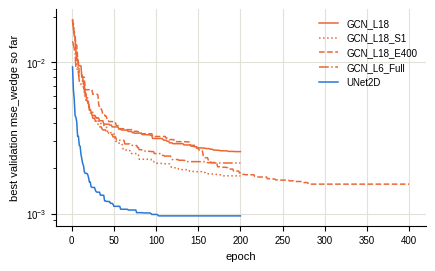

In [17]:
BUDGET_RUNS = ["UNet2D", "GCN_L6", "GCN_L6_Full", "GCN_L18", "GCN_L18_S1", "GCN_L18_E400", "SNN_L18", "SNN_L18_S1"]
COMPARISONS_7 = [  # (question, reference, candidate)
    ("budget", "GCN_L18", "GCN_L18_E400"), ("budget", "GCN_L18_S1", "GCN_L18_E400"),
    ("locality", "GCN_L6", "GCN_L6_Full"), ("locality", "GCN_L18", "GCN_L6_Full"), ("locality", "GCN_L18_S1", "GCN_L6_Full"),
]


def training_summary(name: str) -> dict:
    stats_path = CHECKPOINT_DIR / run_name_of(name) / "training_stats.json"
    if not stats_path.exists():
        return {}
    stats = json.loads(stats_path.read_text())
    gpu_hours = stats["training_time_seconds"] / 3600 * stats.get("world_size", 1)
    return {"Epochs (best)": f"{stats['epochs_run']} ({stats['best']['best_epoch']})", "GPU-hours": f"{gpu_hours:.1f}"}


present_7 = [m for m in BUDGET_RUNS if m in per_sample]
if not {"GCN_L18_E400", "GCN_L6_Full"} & set(present_7):
    print("Not evaluated yet: GCN_L18_E400 and GCN_L6_Full (train them, then python -m src.evaluate).")
else:
    unet = per_sample["UNet2D"]["mse_wedge"].mean()
    rows = []
    for name in present_7:
        projected = per_sample.get(f"{name}_P4")
        mse = per_sample[name]["mse_wedge"].mean()
        rows.append({"Model": name, "mse_wedge": f"{mse:.2e}", "Ratio to UNet2D": f"{mse / unet:.2f}",
                     "mse_wedge + P4": f"{projected['mse_wedge'].mean():.2e}" if projected is not None else "—",
                     "img_psnr": f"{per_sample[name]['img_psnr'].mean():.2f}", **training_summary(name)})
    budget_table = pd.DataFrame(rows).set_index("Model").fillna("—")
    display(budget_table)
    export_table(budget_table, "budget_locality_metrics")

    rows = [{"Question": question, "Comparison": f"{candidate} vs {reference}",
             **paired_change(per_sample[reference]["mse_wedge"], per_sample[candidate]["mse_wedge"])}
            for question, reference, candidate in COMPARISONS_7 if reference in per_sample and candidate in per_sample]
    budget_comparisons = with_holm(pd.DataFrame(rows).set_index(["Question", "Comparison"]))
    display(budget_comparisons)
    export_table(budget_comparisons, "budget_locality_comparisons")

    def beats(candidate: str, references: list) -> bool:
        """Lower mean mse_wedge than every reference, each with a Holm-adjusted p < 0.05."""
        keys = [(question, f"{candidate} vs {ref}") for question, ref, cand in COMPARISONS_7 if cand == candidate
                and ref in references]
        found = [k for k in keys if k in budget_comparisons.index]
        return bool(found) and len(found) == len(references) and all(
            budget_comparisons.loc[k, "Change [95 % CI]"].startswith("-") and float(budget_comparisons.loc[k, "p (Holm)"]) < 0.05
            for k in found)

    gcn_l18_seeds = [m for m in ("GCN_L18", "GCN_L18_S1") if m in per_sample]
    if "GCN_L18_E400" in per_sample:
        ratio = per_sample["GCN_L18_E400"]["mse_wedge"].mean() / unet
        print(("Budget: GCN_L18_E400 beats every 200-epoch seed of GCN_L18, the 200-epoch budget limited the GCN."
               if beats("GCN_L18_E400", gcn_l18_seeds) else
               "Budget: GCN_L18_E400 does not beat every 200-epoch seed of GCN_L18, no budget effect beyond the seed noise.")
              + f" Remaining gap: {ratio:.2f} x the mse_wedge of UNet2D.")
    if "GCN_L6_Full" in per_sample:
        ratio = per_sample["GCN_L6_Full"]["mse_wedge"].mean() / unet
        if beats("GCN_L6_Full", gcn_l18_seeds):
            verdict = "the full graph at 6 layers beats every seed of GCN_L18: the locality of the kNN graph is a limit"
        elif beats("GCN_L6_Full", ["GCN_L6"]):
            verdict = "the full graph removes the reach limit of GCN_L6, but does not replace depth"
        else:
            verdict = "the full graph does not improve GCN_L6: the reach is not what limits it"
        print(f"Locality: {verdict}. Remaining gap: {ratio:.2f} x the mse_wedge of UNet2D.")

    # Validation curves: is GCN_L18 still improving at the end of 200 epochs?
    fig, ax = plt.subplots(figsize=(0.7 * THESIS_W, 2.6), layout="constrained")
    for name, style in (("GCN_L18", "-"), ("GCN_L18_S1", ":"), ("GCN_L18_E400", "--"), ("GCN_L6_Full", "-."),
                        ("UNet2D", "-")):
        history_path = CHECKPOINT_DIR / run_name_of(name) / "history.json"
        if not history_path.exists():
            continue
        history = pd.DataFrame(json.loads(history_path.read_text()))
        ax.plot(history["epoch"], history["val/mse_wedge"].cummin(), linestyle=style, linewidth=1.1,
                color=FAMILY_COLORS.get(family(name), "#898781"), label=name)
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("best validation mse_wedge so far")
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)
    fig.savefig(FIG_DIR / "budget_validation_curves.pdf", bbox_inches="tight")
    plt.show()
